In [1]:
import pathlib
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt




import SessionTools.two_photon as st2p
import el_hd_plasticity.two_photon as nmp


plt.rcParams['pdf.fonttype']=42

%load_ext autoreload
%autoreload 2 


%matplotlib inline


In [2]:
basedir = pathlib.Path('/media/mplitt/SSD_storage/2P_scratch/R18B05LexA_CsChrimsontdT_R60D05Gal4_jGCaMP7f/remapping')
base_sess_df = nmp.remapping.load_sess_df(basedir, 'base')
mask = []
for _, row in base_sess_df.iterrows():
    if row['condition'] in set(['epinastine', 'yohimbine']):
        mask.append(False)
    else:
        mask.append(True)
base_sess_df = base_sess_df.loc[mask].reset_index(drop=True)

basedir = pathlib.Path('/media/mplitt/SSD_storage/2P_scratch/R18B05LexA_CsChrimsontdT_R60D05Gal4_jGCaMP7f_hcKCR1')
hckcr_sess_df = nmp.remapping.load_sess_df(basedir, 'hckcr')
# sess_df = nmp.remapping.load_sess_df(basedir, 'hckcr')

# min_cols = ['fly_id', 'date', 'fly', 'session', 'condition', 'scan_type', 'usable', 'folder', 'basedir', 'mean offset', 'offset var.', 'mean vec. len']
sess_df = pd.concat([base_sess_df, hckcr_sess_df], ignore_index=True)

In [3]:
figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/GOF_combined')
figfolder.mkdir(parents=True, exist_ok=True)

In [4]:
load_row = nmp.loading.make_load_row(basedir_col='basedir', folder_cols=('condition',))

In [5]:
for index,row in sess_df.iterrows():
    ts = nmp.session.GetTS(load_row(row))
    
    
    offset_c_mu = ts.offset_c.mean()
    
    sess_df.loc[index, 'mean offset'] = np.angle(offset_c_mu)
    sess_df.loc[index, 'mean vec. len'] = np.abs(offset_c_mu)
    sess_df.loc[index, 'offset var.'] = sp.stats.circvar(ts.offset)

In [6]:
# deg0 = sess_df.loc[(sess_df['condition'] == 'exp') & (sess_df['scan_type'] == 'post_0deg'),'mean offset'] 
# deg180 = sess_df.loc[(sess_df['condition'] == 'exp') & (sess_df['scan_type'] == 'post_180deg'),'mean offset']

# fig, ax = plt.subplots(figsize=(3, 3))
# ax.hist(deg0, bins=30, density=True, alpha=0.5, label='0 deg')
# ax.hist(deg180, bins=30, density=True, alpha=0.5, label='180 deg')

In [7]:
opto_responses = {
    'el chrimson': {'remap_0deg': [], 'remap_180deg': [], 'combined':[]}, 
    'no chrimson': {'remap_0deg': [], 'remap_180deg': [], 'combined': []}, 
    'novis_control': {'remap_novis': []},
    'epg hckcr': {'remap_0deg': [], 'remap_180deg': [], 'combined': []},
    'el chrimson, epg hckcr': {'remap_0deg': [], 'remap_180deg': [], 'combined': []},
}

##
opto_responses['el chrimson']['remap_0deg'] = nmp.remapping.stack_opto_responses(sess_df, load_row, 'remap', 'base', 'remap_0deg')
opto_responses['no chrimson']['remap_0deg'] = nmp.remapping.stack_opto_responses(sess_df, load_row, 'no_chrimson', 'base', 'remap_0deg')
opto_responses['epg hckcr']['remap_0deg'] = nmp.remapping.stack_opto_responses(sess_df, load_row, 'no_cschrimson', 'hckcr', 'remap_0deg')
opto_responses['el chrimson, epg hckcr']['remap_0deg'] = nmp.remapping.stack_opto_responses(sess_df, load_row, 'exp', 'hckcr', 'remap_0deg')

##
opto_responses['el chrimson']['remap_180deg'] = nmp.remapping.stack_opto_responses(sess_df, load_row, 'remap', 'base', 'remap_180deg')
opto_responses['no chrimson']['remap_180deg'] = nmp.remapping.stack_opto_responses(sess_df, load_row, 'no_chrimson', 'base', 'remap_180deg')
opto_responses['epg hckcr']['remap_180deg'] = nmp.remapping.stack_opto_responses(sess_df, load_row, 'no_cschrimson', 'hckcr', 'remap_180deg')
opto_responses['el chrimson, epg hckcr']['remap_180deg'] = nmp.remapping.stack_opto_responses(sess_df, load_row, 'exp', 'hckcr', 'remap_180deg')

##
opto_responses['novis_control']['remap_novis'] = nmp.remapping.stack_opto_responses(sess_df, load_row, 'novis_control', 'base', 'remap_novis')

##
opto_responses['el chrimson']['combined'] = (opto_responses['el chrimson']['remap_0deg'] + opto_responses['el chrimson']['remap_180deg'])/2
opto_responses['no chrimson']['combined'] = (opto_responses['no chrimson']['remap_0deg'] + opto_responses['no chrimson']['remap_180deg'])/2
opto_responses['epg hckcr']['combined'] = (opto_responses['epg hckcr']['remap_0deg'] + opto_responses['epg hckcr']['remap_180deg'])/2
opto_responses['el chrimson, epg hckcr']['combined'] = (opto_responses['el chrimson, epg hckcr']['remap_0deg'] + opto_responses['el chrimson, epg hckcr']['remap_180deg'])/2

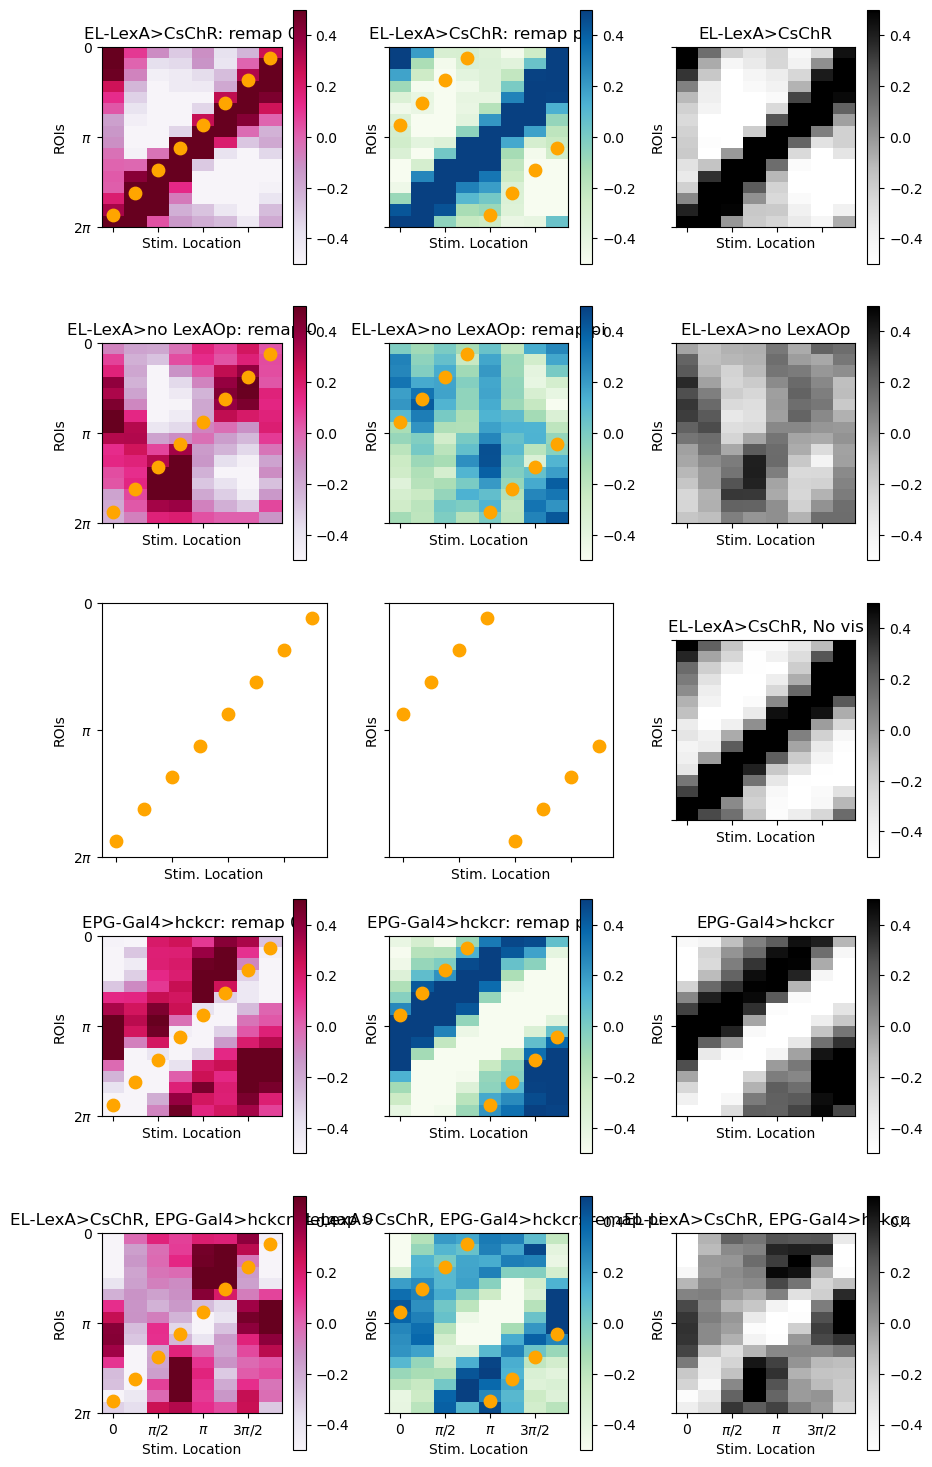

In [8]:
fig, ax = plt.subplots(5,3,figsize=[9,15],sharex=True,sharey=True)

h = ax[0,0].imshow(np.nanmean(opto_responses['el chrimson']['remap_0deg'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='PuRd')
fig.colorbar(h, ax=ax[0,0])
h = ax[0,1].imshow(np.nanmean(opto_responses['el chrimson']['remap_180deg'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='GnBu')
fig.colorbar(h, ax=ax[0,1])
h = ax[0,2].imshow(np.nanmean(opto_responses['el chrimson']['combined'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='Greys')
fig.colorbar(h, ax=ax[0,2])

ax[0, 0].set_title('EL-LexA>CsChR: remap 0')
ax[0, 1].set_title('EL-LexA>CsChR: remap pi')
ax[0, 2].set_title('EL-LexA>CsChR')


h = ax[1,0].imshow(np.nanmean(opto_responses['no chrimson']['remap_0deg'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='PuRd')
fig.colorbar(h, ax=ax[1,0])
h = ax[1,1].imshow(np.nanmean(opto_responses['no chrimson']['remap_180deg'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='GnBu')
fig.colorbar(h, ax=ax[1,1])
h = ax[1,2].imshow(np.nanmean(opto_responses['no chrimson']['combined'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='Greys')
fig.colorbar(h, ax=ax[1,2])

ax[1, 0].set_title('EL-LexA>no LexAOp: remap 0')
ax[1, 1].set_title('EL-LexA>no LexAOp: remap pi')
ax[1, 2].set_title('EL-LexA>no LexAOp')

h = ax[2,2].imshow(np.nanmean(opto_responses['novis_control']['remap_novis'],axis=(0,3)), aspect=.5, vmin=-.5, vmax=.5, cmap='Greys')
fig.colorbar(h, ax=ax[2,2])

ax[2,2].set_title('EL-LexA>CsChR, No vis')

h = ax[3,0].imshow(np.nanmean(opto_responses['epg hckcr']['remap_0deg'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='PuRd')
fig.colorbar(h, ax=ax[3,0])
h = ax[3,1].imshow(np.nanmean(opto_responses['epg hckcr']['remap_180deg'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='GnBu')
fig.colorbar(h, ax=ax[3,1])
h = ax[3,2].imshow(np.nanmean(opto_responses['epg hckcr']['combined'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='Greys')
fig.colorbar(h, ax=ax[3,2])

ax[3, 0].set_title('EPG-Gal4>hckcr: remap 0')
ax[3, 1].set_title('EPG-Gal4>hckcr: remap pi')
ax[3, 2].set_title('EPG-Gal4>hckcr')

h = ax[4,0].imshow(np.nanmean(opto_responses['el chrimson, epg hckcr']['remap_0deg'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='PuRd')
fig.colorbar(h, ax=ax[4,0])
h = ax[4,1].imshow(np.nanmean(opto_responses['el chrimson, epg hckcr']['remap_180deg'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='GnBu')
fig.colorbar(h, ax=ax[4,1])
h = ax[4,2].imshow(np.nanmean(opto_responses['el chrimson, epg hckcr']['combined'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='Greys')
fig.colorbar(h, ax=ax[4,2])
ax[4, 0].set_title('EL-LexA>CsChR, EPG-Gal4>hckcr: remap 0')
ax[4, 1].set_title('EL-LexA>CsChR, EPG-Gal4>hckcr: remap pi')
ax[4, 2].set_title('EL-LexA>CsChR, EPG-Gal4>hckcr')



for r in range(5):
    x = np.arange(8)
    y = np.arange(0,2*np.pi,np.pi/4)[::-1]*8/np.pi+.5
    h = ax[r,0].scatter(x,y,color= 'orange',s=80)


    y = np.roll(y,4)
    ax[r,1].scatter(x,y,color='orange',s=80)
    

for a in ax.flatten():
    a.set_ylabel('ROIs')
    a.set_xlabel('Stim. Location')
    
    a.set_xticks([0,2,4,6], labels=[r'0',r'$\pi$/2', r'$\pi$', r'3$\pi$/2'])
    a.set_yticks([-.5,7.5,15.5], labels=[r'0',r'$\pi$', r'2$\pi$'])

fig.tight_layout()
fig.savefig(figfolder / 'opto_responses.pdf', bbox_inches='tight', dpi=300)


In [9]:
opto_resp_al = {}

for ck in opto_responses.keys():
    opto_resp_al[ck] = {}
    for rk in opto_responses[ck].keys():
        opto = np.copy(opto_responses[ck][rk])
        for i in range(8):
            opto[:,:,i,:] = np.roll(opto[:,:,i,:],2*i-8, axis=1)
            
        opto_resp_al[ck][rk] = opto

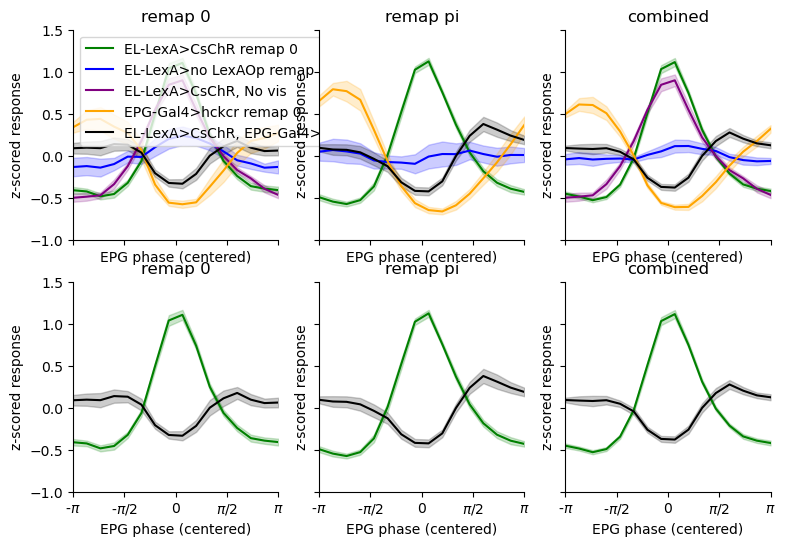

In [10]:
fig, ax = plt.subplots(2,3, figsize=[9,6], sharex=True, sharey=True)
x = np.linspace(-np.pi, np.pi, num=16)

mu, sem = nmp.remapping.get_mu_sem(opto_resp_al, 'el chrimson', 'remap_0deg')
ax[0,0].plot(x, mu, color='green', label='EL-LexA>CsChR remap 0')
ax[0,0].fill_between(x, mu-sem, mu+sem, color='green', alpha=.2)
ax[1,0].plot(x, mu, color='green', label='EL-LexA>CsChR remap 0')
ax[1,0].fill_between(x, mu-sem, mu+sem, color='green', alpha=.2)

mu, sem = nmp.remapping.get_mu_sem(opto_resp_al, 'el chrimson', 'remap_180deg')
ax[0,1].plot(x, mu, color='green', label='EL-LexA>CsChR remap pi')
ax[0,1].fill_between(x, mu-sem, mu+sem, color='green', alpha=.2)
ax[1,1].plot(x, mu, color='green', label='EL-LexA>CsChR remap pi')
ax[1,1].fill_between(x, mu-sem, mu+sem, color='green', alpha=.2)

mu, sem = nmp.remapping.get_mu_sem(opto_resp_al, 'el chrimson', 'combined')
ax[0,2].plot(x, mu, color='green', label='EL-LexA>CsChR combined')
ax[0,2].fill_between(x, mu-sem, mu+sem, color='green', alpha=.2)
ax[1,2].plot(x, mu, color='green', label='EL-LexA>CsChR combined')
ax[1,2].fill_between(x, mu-sem, mu+sem, color='green', alpha=.2)

mu, sem = nmp.remapping.get_mu_sem(opto_resp_al, 'no chrimson', 'remap_0deg')
ax[0,0].plot(x, mu, color='blue', label='EL-LexA>no LexAOp remap 0')
ax[0,0].fill_between(x, mu-sem, mu+sem, color='blue', alpha=.2)
mu, sem = nmp.remapping.get_mu_sem(opto_resp_al, 'no chrimson', 'remap_180deg')
ax[0,1].plot(x, mu, color='blue', label='EL-LexA>no LexAOp remap pi')
ax[0,1].fill_between(x, mu-sem, mu+sem, color='blue', alpha=.2)
mu, sem = nmp.remapping.get_mu_sem(opto_resp_al, 'no chrimson', 'combined')
ax[0,2].plot(x, mu, color='blue', label='EL-LexA>no LexAOp combined')
ax[0,2].fill_between(x, mu-sem, mu+sem, color='blue', alpha=.2)

mu, sem = nmp.remapping.get_mu_sem(opto_resp_al, 'novis_control', 'remap_novis')
ax[0,0].plot(x, mu, color='purple', label='EL-LexA>CsChR, No vis')
ax[0,0].fill_between(x, mu-sem, mu+sem, color='purple', alpha=.2)
ax[0,2].plot(x, mu, color='purple', label='EL-LexA>CsChR, No vis')
ax[0,2].fill_between(x, mu-sem, mu+sem, color='purple', alpha=.2)

mu, sem = nmp.remapping.get_mu_sem(opto_resp_al, 'epg hckcr', 'remap_0deg')
ax[0,0].plot(x, mu, color='orange', label='EPG-Gal4>hckcr remap 0')
ax[0,0].fill_between(x, mu-sem, mu+sem, color='orange', alpha=.2)
mu, sem = nmp.remapping.get_mu_sem(opto_resp_al, 'epg hckcr', 'remap_180deg')
ax[0,1].plot(x, mu, color='orange', label='EPG-Gal4>hckcr remap pi')
ax[0,1].fill_between(x, mu-sem, mu+sem, color='orange', alpha=.2)
mu, sem = nmp.remapping.get_mu_sem(opto_resp_al, 'epg hckcr', 'combined')
ax[0,2].plot(x, mu, color='orange', label='EPG-Gal4>hckcr combined')
ax[0,2].fill_between(x, mu-sem, mu+sem, color='orange', alpha=.2)

mu, sem = nmp.remapping.get_mu_sem(opto_resp_al, 'el chrimson, epg hckcr', 'remap_0deg')
ax[0,0].plot(x, mu, color='black', label='EL-LexA>CsChR, EPG-Gal4>hckcr remap 0')
ax[0,0].fill_between(x, mu-sem, mu+sem, color='black', alpha=.2)
ax[1,0].plot(x, mu, color='black', label='EL-LexA>CsChR, EPG-Gal4>hckcr remap 0')
ax[1,0].fill_between(x, mu-sem, mu+sem, color='black', alpha=.2)
mu, sem = nmp.remapping.get_mu_sem(opto_resp_al, 'el chrimson, epg hckcr', 'remap_180deg')
ax[0,1].plot(x, mu, color='black', label='EL-LexA>CsChR, EPG-Gal4>hckcr remap pi')
ax[0,1].fill_between(x, mu-sem, mu+sem, color='black', alpha=.2)
ax[1,1].plot(x, mu, color='black', label='EL-LexA>CsChR, EPG-Gal4>hckcr remap pi')
ax[1,1].fill_between(x, mu-sem, mu+sem, color='black', alpha=.2)
mu, sem = nmp.remapping.get_mu_sem(opto_resp_al, 'el chrimson, epg hckcr', 'combined')
ax[0,2].plot(x, mu, color='black', label='EL-LexA>CsChR, EPG-Gal4>hckcr combined')
ax[0,2].fill_between(x, mu-sem, mu+sem, color='black', alpha=.2)
ax[1,2].plot(x, mu, color='black', label='EL-LexA>CsChR, EPG-Gal4>hckcr combined')
ax[1,2].fill_between(x, mu-sem, mu+sem, color='black', alpha=.2)

ax[0,0].legend()
ax[0,0].set_title('remap 0')
ax[0,1].set_title('remap pi')
ax[0,2].set_title('combined')
ax[1,0].set_title('remap 0')
ax[1,1].set_title('remap pi')
ax[1,2].set_title('combined')

for a in ax.flatten():
    a.set_xlabel('EPG phase (centered)')
    a.set_ylabel('z-scored response')
    a.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi], labels=[r'-$\pi$', r'-$\pi$/2', r'0', r'$\pi$/2', r'$\pi$'])
    # a.set_xticks([0,2,4,6], labels=[r'0',r'$\pi$/2', r'$\pi$', r'3$\pi$/2'])
    # a.set_yticks([-1,0,1], labels=[-1,0,1])
    a.set_xlim(-np.pi,np.pi)
    a.set_ylim(-1,1.5)
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

# fig.tight_layout()
fig.savefig(figfolder / 'opto_responses_aligned.pdf')

In [12]:
flies = sess_df['fly_id'].unique()
conditions = []
for fly in flies:
    row = sess_df.loc[sess_df['fly_id']==fly].iloc[0]
    if row['condition'] == 'remap' and row['folder'] == 'base':
        conditions.append('EL>CsChR')
    elif row['condition'] == 'no_chrimson' and row['folder'] == 'base':
        conditions.append('EL>empty')
    elif row['condition'] == 'novis_control' and row['folder'] == 'base':
        conditions.append('EL>CsChR, No vis')
    elif row['condition'] == 'no_cschrimson' and row['folder'] == 'hckcr':
        conditions.append('EPG>hckcr')
    elif row['condition'] == 'exp' and row['folder'] == 'hckcr':
        conditions.append('EL>CsChR, EPG>hckcr')
        # print(fly)
    else:
        pass

# for f, c in zip(flies, conditions):
#     print(f, c)
sum_stats = nmp.remapping.build_sum_stats(sess_df.loc[sess_df['scan_type'].isin(['baseline', 'post_0deg', 'post_180deg', 'post_novis1', 'post_novis2'])], flies, conditions=conditions,
                               scan_types=nmp.remapping.ALL_SCAN_TYPES)

In [25]:
conditions = []
for _, row  in sess_df.iterrows():
    if row['condition'] == 'remap' and row['folder'] == 'base':
        conditions.append('EL>CsChR')
    elif row['condition'] == 'no_chrimson' and row['folder'] == 'base':
        conditions.append('EL>empty')
    elif row['condition'] == 'novis_control' and row['folder'] == 'base':
        conditions.append('EL>CsChR, No vis')
    elif row['condition'] == 'no_cschrimson' and row['folder'] == 'hckcr':
        conditions.append('EPG>hckcr')
    elif row['condition'] == 'exp' and row['folder'] == 'hckcr':
        conditions.append('EL>CsChR, EPG>hckcr')
        # print(fly)
    else:
        conditions.append('other')

sess_df['condition_full'] = conditions

EL>CsChR remap 0 -0.028051328376471625
EL>CsChR remap 180 3.1206438181171876
EL>empty remap 0 0.35215337824271326
EL>empty remap 180 -0.23580344636448694
EPG>hckcr remap 0 0.5264228671400265
EPG>hckcr remap 180 0.6614072027681149
EL>CsChR, EPG>hckcr remap 0 0.2383904592116349
EL>CsChR, EPG>hckcr remap 180 -2.8677051495253427


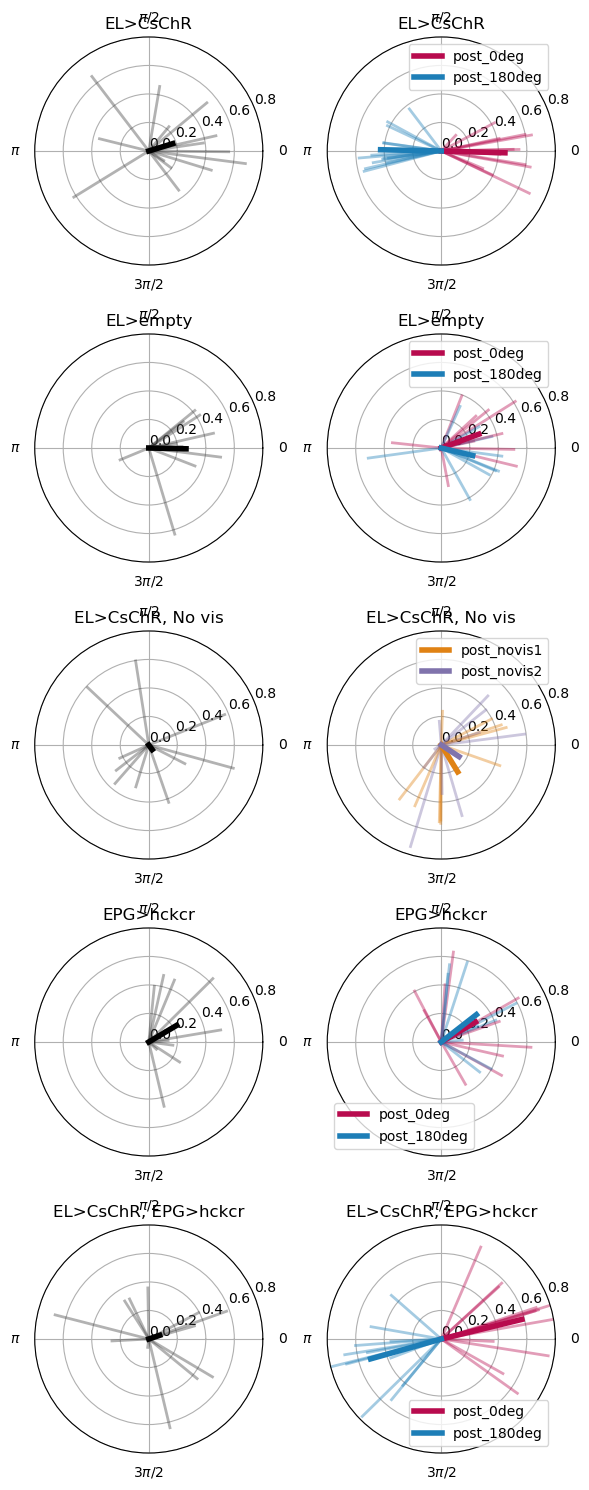

In [14]:
fig, ax = plt.subplots(5, 2, subplot_kw={'projection':'polar'}, figsize=[6,15], sharex=True, sharey=True)

nmp.remapping.plot_row_sum_stats(sum_stats, ax, 0, 'EL>CsChR')
nmp.remapping.plot_row_sum_stats(sum_stats, ax, 1, 'EL>empty')
nmp.remapping.plot_row_sum_stats(sum_stats, ax, 2, 'EL>CsChR, No vis', novis=True)
nmp.remapping.plot_row_sum_stats(sum_stats, ax, 3, 'EPG>hckcr')
nmp.remapping.plot_row_sum_stats(sum_stats, ax, 4, 'EL>CsChR, EPG>hckcr')

fig.tight_layout()
fig.savefig(figfolder / 'sum_stats_polar.pdf')

In [15]:
print(np.pi/16, -np.pi + np.pi/16)


0.19634954084936207 -2.945243112740431


In [16]:
sum_stats

,fly_id,condition,baseline mean offset,baseline vec. len,baseline offset var.,post_0deg mean offset,post_0deg vec. len,post_0deg offset var.,post_180deg mean offset,post_180deg vec. len,post_180deg offset var.,post_novis1 mean offset,post_novis1 vec. len,post_novis1 offset var.,post_novis2 mean offset,post_novis2 vec. len,post_novis2 offset var.
0,11_07_2024_fly1_remap_base,EL>CsChR,-0.297471,0.458384,0.541616,-0.160008,0.595068,0.404932,-3.007451,0.373136,0.626864,NaN,NaN,NaN,NaN,NaN,NaN
1,15_07_2024_fly1_remap_base,EL>CsChR,-0.647330,0.193653,0.806347,-0.057459,0.411714,0.588286,3.004484,0.407184,0.592816,NaN,NaN,NaN,NaN,NaN,NaN
2,18_07_2024_fly1_remap_base,EL>CsChR,0.223111,0.482829,0.517171,0.195338,0.598303,0.401697,-3.081782,0.488026,0.511974,NaN,NaN,NaN,NaN,NaN,NaN
3,18_07_2024_fly2_remap_base,EL>CsChR,0.692647,0.529232,0.470768,0.020037,0.545128,0.454872,-2.971829,0.484066,0.515934,NaN,NaN,NaN,NaN,NaN,NaN
4,18_07_2024_fly3_remap_base,EL>CsChR,-2.589927,0.617202,0.382798,-0.447636,0.684617,0.315383,-2.912882,0.545727,0.454273,NaN,NaN,NaN,NaN,NaN,NaN
5,01_08_2024_fly2_remap_base,EL>CsChR,-0.918561,0.345713,0.654287,0.825834,0.149907,0.850093,-2.927840,0.389178,0.610822,NaN,NaN,NaN,NaN,NaN,NaN
6,01_08_2024_fly3_remap_base,EL>CsChR,2.898085,0.356221,0.643779,-0.178204,0.633545,0.366455,2.643864,0.427886,0.572114,NaN,NaN,NaN,NaN,NaN,NaN
7,01_08_2024_fly4_remap_base,EL>CsChR,0.145027,0.385728,0.614272,-0.436990,0.393782,0.606218,2.702549,0.416709,0.583291,NaN,NaN,NaN,NaN,NaN,NaN
8,01_08_2024_fly5_remap_base,EL>CsChR,2.222797,0.657611,0.342389,0.175409,0.642239,0.357761,2.999817,0.406430,0.593570,NaN,NaN,NaN,NaN,NaN,NaN
9,02_08_2024_fly2_remap_base,EL>CsChR,0.878965,0.221272,0.778728,0.487402,0.422656,0.577344,-3.002291,0.414484,0.585516,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
sum_stats.loc[sum_stats['condition']=='EPG>hckcr']

,fly_id,condition,baseline mean offset,baseline vec. len,baseline offset var.,post_0deg mean offset,post_0deg vec. len,post_0deg offset var.,post_180deg mean offset,post_180deg vec. len,post_180deg offset var.,post_novis1 mean offset,post_novis1 vec. len,post_novis1 offset var.,post_novis2 mean offset,post_novis2 vec. len,post_novis2 offset var.
34,14_05_2025_fly1_no_cschrimson_hckcr,EPG>hckcr,0.780291,0.632035,0.367965,0.518945,0.621052,0.378948,1.256035,0.587883,0.412117,NaN,NaN,NaN,NaN,NaN,NaN
35,14_05_2025_fly2_no_cschrimson_hckcr,EPG>hckcr,-0.576475,0.257857,0.742143,-0.505518,0.482859,0.517141,0.414254,0.277703,0.722297,NaN,NaN,NaN,NaN,NaN,NaN
36,14_05_2025_fly3_no_cschrimson_hckcr,EPG>hckcr,-0.762579,0.073292,0.926708,2.053739,0.403512,0.596488,0.380090,0.411312,0.588688,NaN,NaN,NaN,NaN,NaN,NaN
37,14_05_2025_fly4_no_cschrimson_hckcr,EPG>hckcr,1.351745,0.478314,0.521686,1.436723,0.636232,0.363768,1.464825,0.544810,0.455190,NaN,NaN,NaN,NaN,NaN,NaN
38,15_05_2025_fly1_no_cschrimson_hckcr,EPG>hckcr,0.074969,0.136019,0.863981,-0.224577,0.440470,0.559530,-0.495473,0.397353,0.602647,NaN,NaN,NaN,NaN,NaN,NaN
39,15_05_2025_fly2_no_cschrimson_hckcr,EPG>hckcr,-0.131846,0.170377,0.829623,0.340207,0.431139,0.568861,0.652613,0.316173,0.683827,NaN,NaN,NaN,NaN,NaN,NaN
40,15_05_2025_fly3_no_cschrimson_hckcr,EPG>hckcr,0.165635,0.511563,0.488437,-0.058910,0.629982,0.370018,0.477073,0.589517,0.410483,NaN,NaN,NaN,NaN,NaN,NaN
41,16_05_2025_fly1_no_cschrimson_hckcr,EPG>hckcr,1.178064,0.470075,0.529925,1.505963,0.401940,0.598060,1.473299,0.477408,0.522592,NaN,NaN,NaN,NaN,NaN,NaN
42,16_05_2025_fly2_no_cschrimson_hckcr,EPG>hckcr,1.471659,0.392574,0.607426,2.069989,0.249977,0.750023,0.089359,0.147206,0.852794,NaN,NaN,NaN,NaN,NaN,NaN
43,16_05_2025_fly3_no_cschrimson_hckcr,EPG>hckcr,-1.337533,0.463243,0.536757,-1.051477,0.341640,0.658360,-0.663892,0.341646,0.658354,NaN,NaN,NaN,NaN,NaN,NaN


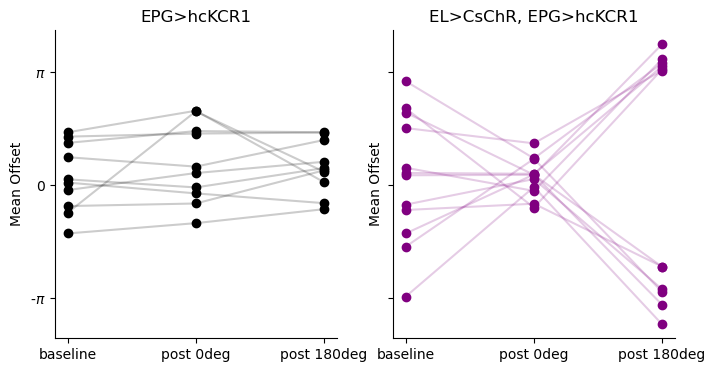

In [35]:
fig, ax = plt.subplots(1,2, figsize=[8,4], sharex=True, sharey=True)

nmp.remapping.plot_min_dist(sum_stats.loc[sum_stats['condition']=='EPG>hckcr',:], ax[0], color='black', novis=False)
nmp.remapping.plot_min_dist(sum_stats.loc[sum_stats['condition']=='EL>CsChR, EPG>hckcr',:], ax[1], color='purple', novis=False)


for a in ax.flatten():
    a.set_xticks([0,1,2], ['baseline', 'post 0deg', 'post 180deg'])
    a.set_yticks([-np.pi,0,np.pi], [r'-$\pi$', '0', r'$\pi$'])
    a.set_ylabel('Mean Offset')
    
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
ax[0].set_title('EPG>hcKCR1')
ax[1].set_title('EL>CsChR, EPG>hcKCR1')

fig.savefig(figfolder / 'el_cschr_epg_hckcr_remapping_offsets.pdf')


In [26]:
sess_df['condition_full'].unique()

array(['EL>CsChR', 'EL>CsChR, No vis', 'EL>empty', 'EPG>hckcr',
       'EL>CsChR, EPG>hckcr'], dtype=object)

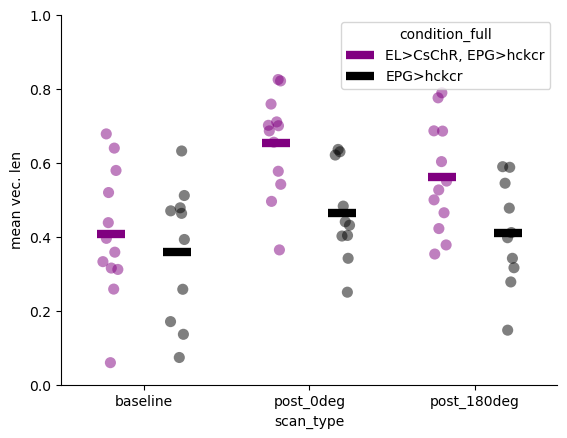

In [34]:
import seaborn as sns
fig, ax = plt.subplots()

colors = ['purple', 'black']
tmp_sess_df = sess_df.loc[sess_df['scan_type'].isin(('baseline', 'post_0deg', 'post_180deg'))]
tmp_sess_df = tmp_sess_df.loc[tmp_sess_df['condition_full'].isin(('EPG>hckcr', 'EL>CsChR, EPG>hckcr'))]
# tmp_sess_df.head()
sns.stripplot(data=tmp_sess_df, x='scan_type', y='mean vec. len', ax=ax, alpha=.5,
            dodge=True, palette=colors, hue='condition_full', s=8, legend=False,
            hue_order=['EL>CsChR, EPG>hckcr', 'EPG>hckcr'])
sns.pointplot(data=tmp_sess_df, x='scan_type', y='mean vec. len', ax=ax, 
              hue='condition_full', palette=colors, hue_order=['EL>CsChR, EPG>hckcr', 'EPG>hckcr'],
              estimator=np.mean, errorbar=None, marker='_', markersize=20, 
              markeredgewidth=6, legend=True, dodge=.4, linestyle='none')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylim([0,1])
fig.savefig(figfolder / "hckcr_remapping_vec_len_comparison.pdf")


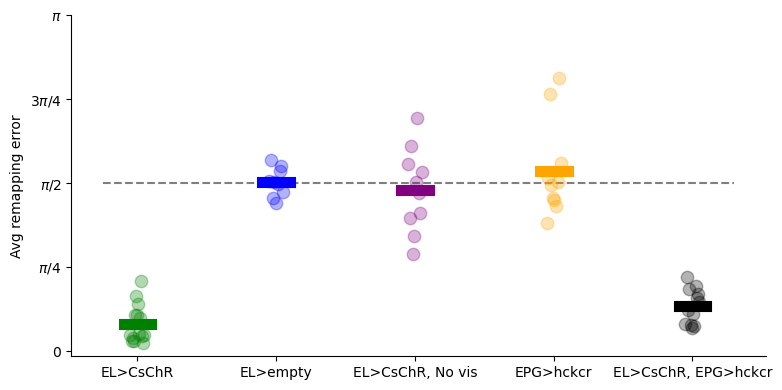

In [21]:
fig, ax = plt.subplots(figsize=[8,4])

cols = ['EL>CsChR', 'EL>empty', 'EL>CsChR, No vis',  'EPG>hckcr', 'EL>CsChR, EPG>hckcr']
colors = ['green', 'blue', 'purple', 'orange', 'black']
avg_diffs = {}
for i, (col, color) in enumerate(zip(cols, colors)):
    sum_stats_col = sum_stats.loc[sum_stats['condition']==col].copy()
    # print(sum_stats_col.head())
    avg_diff_col = nmp.remapping.avg_diff(sum_stats_col, novis=(col == 'EL>CsChR, No vis'))
    avg_diff_col = avg_diff_col.values[~np.isnan(avg_diff_col.values)]

    avg_diffs[col] = avg_diff_col
    
    n = avg_diff_col.shape[0]
    ax.scatter(np.linspace(0,.1,num=n) + i, avg_diff_col, color=color, alpha=.3, s=80)
    ax.plot([-.05+i,.15+i], avg_diff_col.mean()*np.ones([2,]), linewidth=8, color=color, label=col)

ax.plot([-.2,4.35], [np.pi/2, np.pi/2], 'k--', alpha=.5, zorder=-1)

ax.set_xticks(np.arange(5)+.05, labels=cols)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylabel('Avg remapping error')
_ = ax.set_yticks([0,np.pi/4,np.pi/2,3*np.pi/4, np.pi], labels=[0, r"$\pi$/4", r"$\pi$/2", r"$3\pi$/4", r"$\pi$"])

fig.tight_layout()
fig.savefig(figfolder / 'avg_remapping_error.pdf', bbox_inches='tight', dpi=300)


In [22]:
for col in cols:
    t, p = sp.stats.wilcoxon(avg_diffs[col]-np.pi/2)
    N = avg_diffs[col].shape[0]
    print(f"{col} remap error less than chance (pi/2): N={N}, t={t}, p={p}") 
    

EL>CsChR remap error less than chance (pi/2): N=14, t=0.0, p=0.0001220703125
EL>empty remap error less than chance (pi/2): N=9, t=19.0, p=0.734375
EL>CsChR, No vis remap error less than chance (pi/2): N=10, t=24.0, p=0.76953125
EPG>hckcr remap error less than chance (pi/2): N=10, t=25.0, p=0.845703125
EL>CsChR, EPG>hckcr remap error less than chance (pi/2): N=12, t=0.0, p=0.00048828125


In [23]:
t,p = sp.stats.mannwhitneyu(avg_diffs['EL>CsChR'], avg_diffs['EL>CsChR, EPG>hckcr'])
print(f"EL>CsChR vs EL>CsChR, EPG>hckcr: t={t}, p={p}")

EL>CsChR vs EL>CsChR, EPG>hckcr: t=37.0, p=0.016770456126381922


In [24]:
import pingouin as pg


In [25]:
cols = ['EL>CsChR', 'EL>empty', 'EL>CsChR, No vis',  'EPG>hckcr', 'EL>CsChR, EPG>hckcr']
colors = ['green', 'blue', 'purple', 'orange', 'black']
df = []
for i, (col, color) in enumerate(zip(cols, colors)):
    sum_stats_col = sum_stats.loc[sum_stats['condition']==col].copy()
    # print(sum_stats_col.head())
    avg_diff_col = nmp.remapping.avg_diff(sum_stats_col, novis=(col == 'EL>CsChR, No vis'))
    conds = [col for _ in range(avg_diff_col.shape[0])]
    avg_diff_col = pd.DataFrame({'avg_diff': avg_diff_col, 'condition': conds})

    df.append(avg_diff_col)
df = pd.concat(df, axis=0).reset_index(drop=True)

In [26]:
df

,avg_diff,condition
0,0.147075,EL>CsChR
1,0.097284,EL>CsChR
2,0.127574,EL>CsChR
3,0.094901,EL>CsChR
4,0.338173,EL>CsChR
...,...,...
229,0.236551,"EL>CsChR, EPG>hckcr"
230,0.605777,"EL>CsChR, EPG>hckcr"
231,0.496307,"EL>CsChR, EPG>hckcr"
232,0.532860,"EL>CsChR, EPG>hckcr"


In [27]:
kruskal = pg.kruskal(data=df, dv='avg_diff', between='condition')
print(kruskal)

            Source  ddof1          H         p-unc
Kruskal  condition      4  41.878711  1.767573e-08


In [28]:
res = pg.pairwise_ttests(data=df, dv='avg_diff', between='condition', padjust='holm', parametric=False)
print(res)

    Contrast                    A                    B  Paired  Parametric  \
0  condition             EL>CsChR  EL>CsChR, EPG>hckcr   False       False   
1  condition             EL>CsChR     EL>CsChR, No vis   False       False   
2  condition             EL>CsChR             EL>empty   False       False   
3  condition             EL>CsChR            EPG>hckcr   False       False   
4  condition  EL>CsChR, EPG>hckcr     EL>CsChR, No vis   False       False   
5  condition  EL>CsChR, EPG>hckcr             EL>empty   False       False   
6  condition  EL>CsChR, EPG>hckcr            EPG>hckcr   False       False   
7  condition     EL>CsChR, No vis             EL>empty   False       False   
8  condition     EL>CsChR, No vis            EPG>hckcr   False       False   
9  condition             EL>empty            EPG>hckcr   False       False   

   U-val alternative     p-unc    p-corr p-adjust    hedges  
0   37.0   two-sided  0.016770  0.067082     holm -0.915115  
1    0.0   two-si

/home/mplitt/mambaforge/envs/NeuroModPlasticity/lib/python3.11/site-packages/pingouin/pairwise.py:28: UserWarning: pairwise_ttests is deprecated, use pairwise_tests instead.
  warnings.warn("pairwise_ttests is deprecated, use pairwise_tests instead.", UserWarning)


In [29]:
flies = sum_stats.loc[sum_stats['condition']=='EPG>hckcr','fly_id'].tolist() + sum_stats.loc[sum_stats['condition']=='EL>CsChR, EPG>hckcr','fly_id'].tolist()
print(flies)

['14_05_2025_fly1_no_cschrimson_hckcr', '14_05_2025_fly2_no_cschrimson_hckcr', '14_05_2025_fly3_no_cschrimson_hckcr', '14_05_2025_fly4_no_cschrimson_hckcr', '15_05_2025_fly1_no_cschrimson_hckcr', '15_05_2025_fly2_no_cschrimson_hckcr', '15_05_2025_fly3_no_cschrimson_hckcr', '16_05_2025_fly1_no_cschrimson_hckcr', '16_05_2025_fly2_no_cschrimson_hckcr', '16_05_2025_fly3_no_cschrimson_hckcr', '22_05_2025_fly1_exp_hckcr', '22_05_2025_fly2_exp_hckcr', '22_05_2025_fly3_exp_hckcr', '23_05_2025_fly2_exp_hckcr', '23_05_2025_fly3_exp_hckcr', '26_05_2025_fly1_exp_hckcr', '26_05_2025_fly2_exp_hckcr', '26_05_2025_fly3_exp_hckcr', '26_05_2025_fly4_exp_hckcr', '27_05_2025_fly1_exp_hckcr', '27_05_2025_fly2_exp_hckcr', '27_05_2025_fly3_exp_hckcr']


/home/mplitt/repos/NeuromodPlasticity/NeuromodPlasticity/remapping.py:143: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig_polar, ax_polar = plt.subplots(subplot_kw={'projection':'polar'})


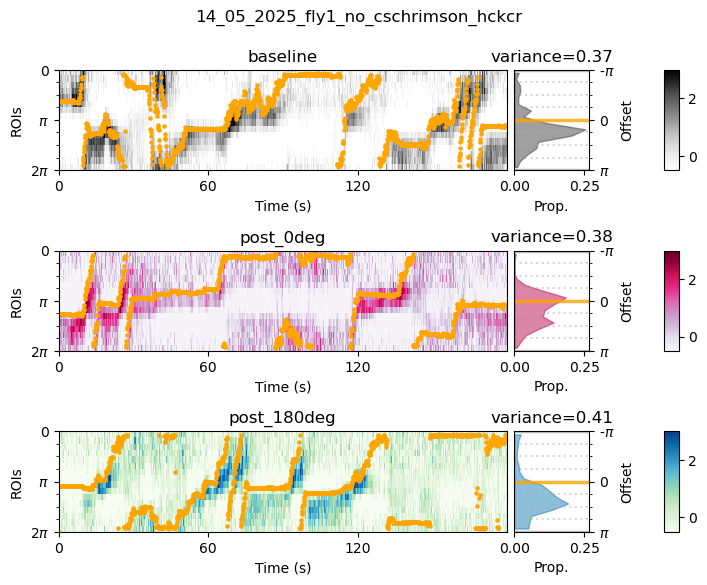

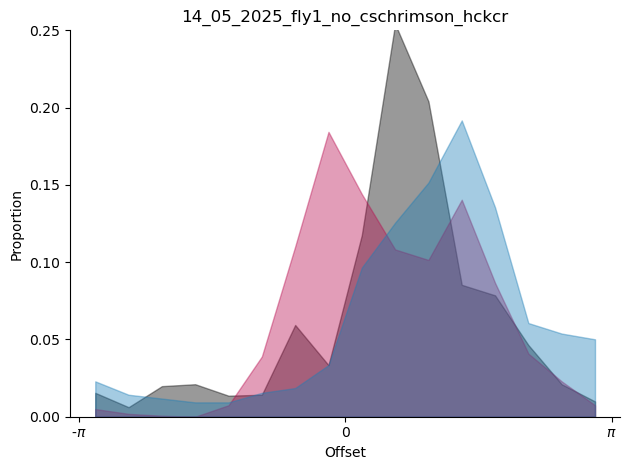

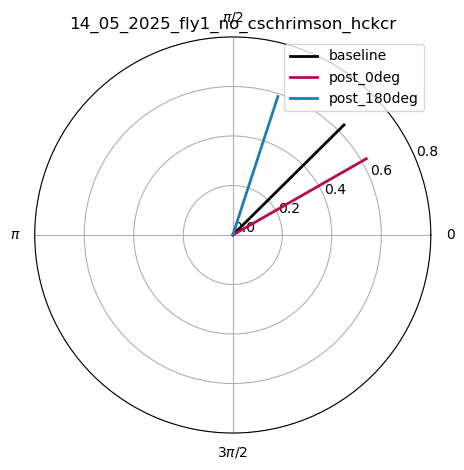

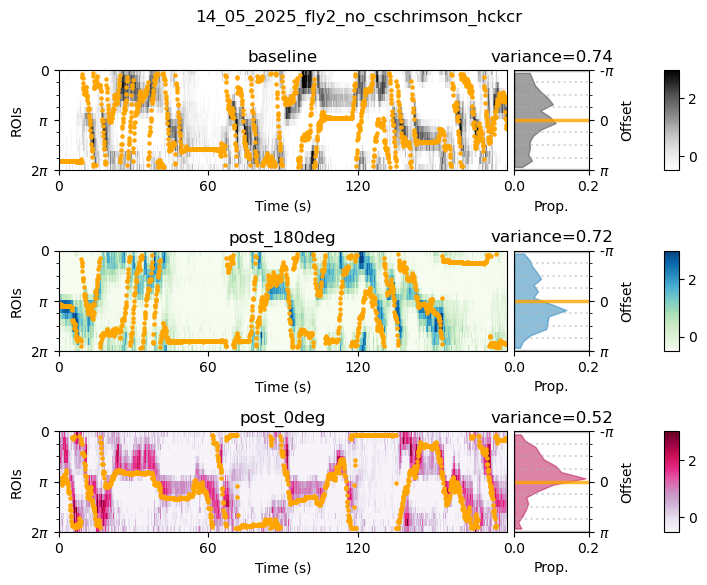

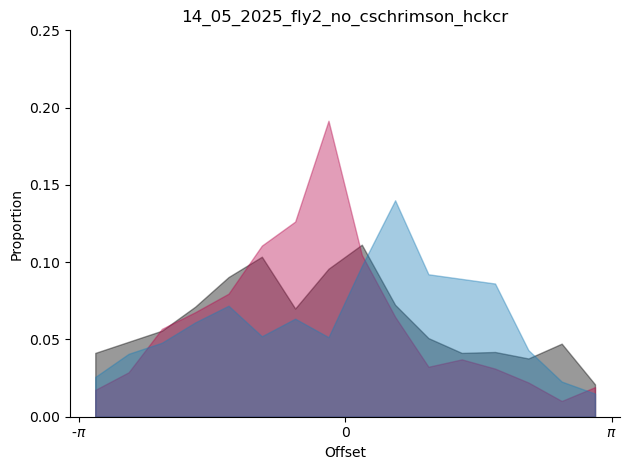

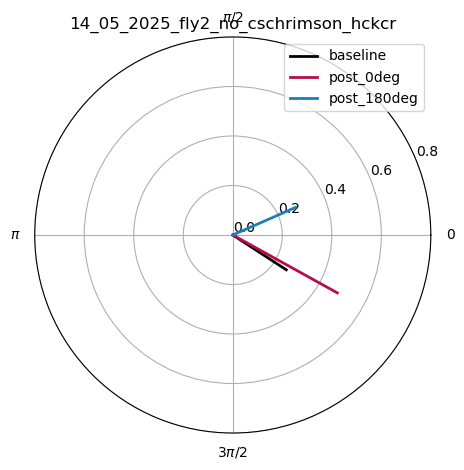

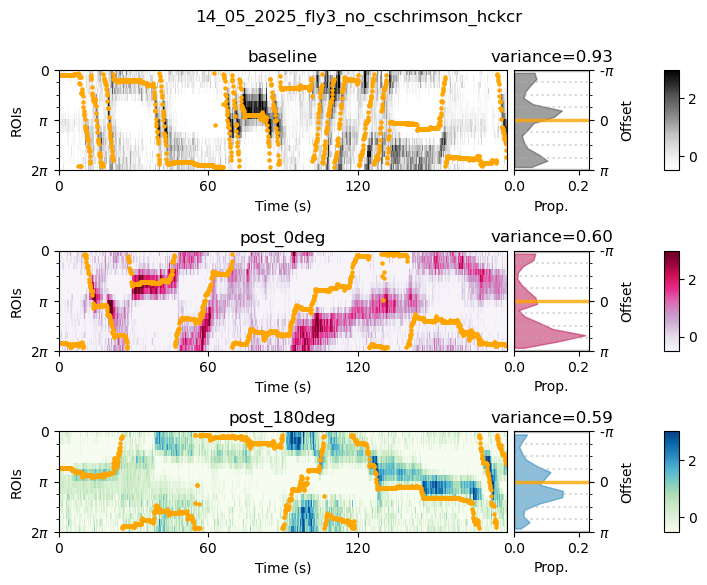

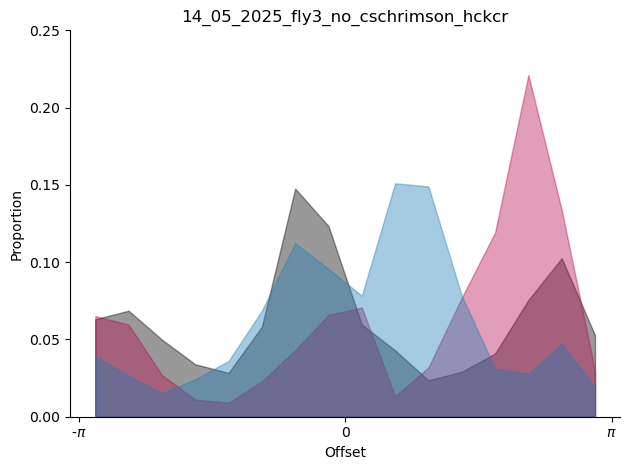

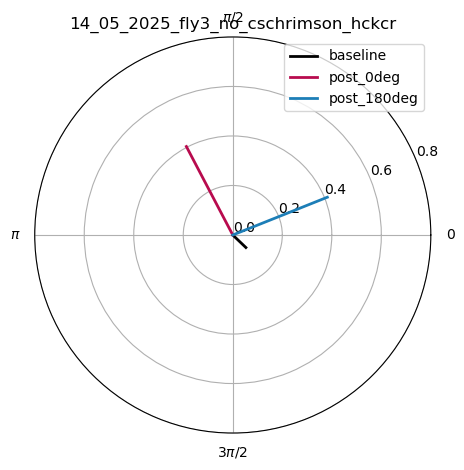

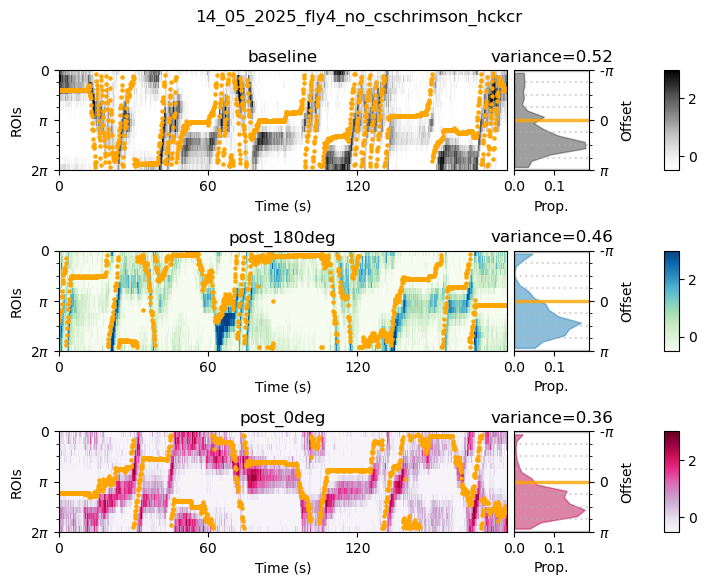

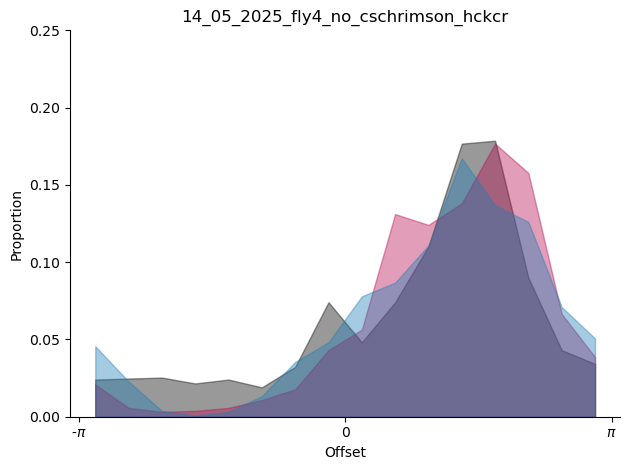

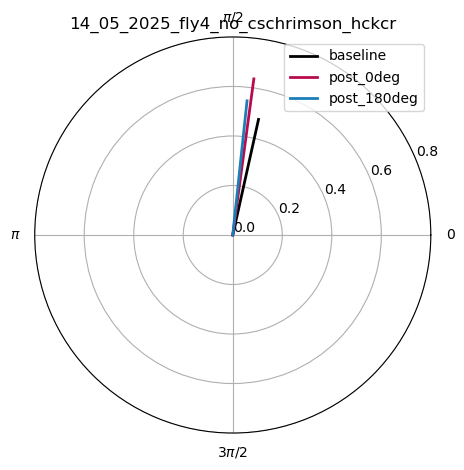

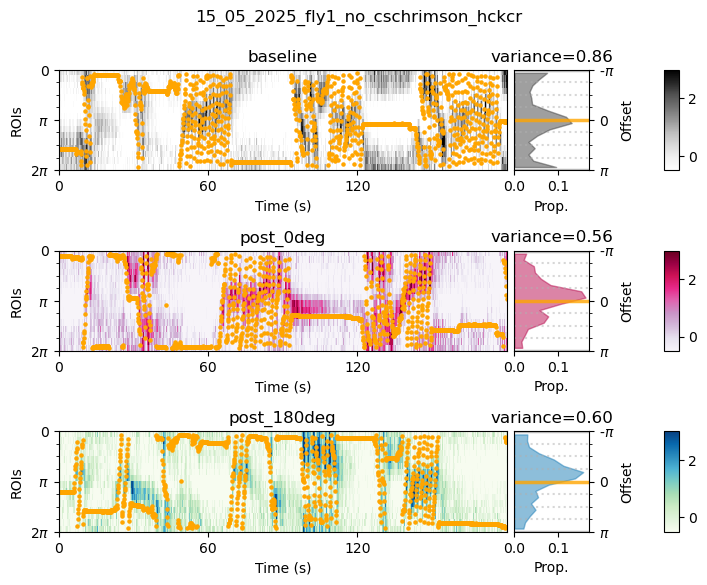

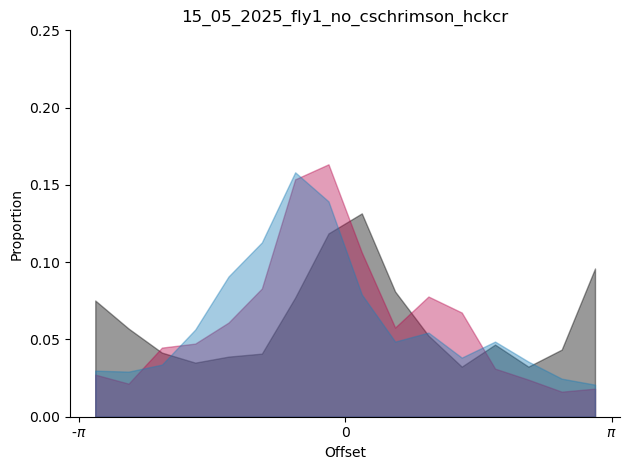

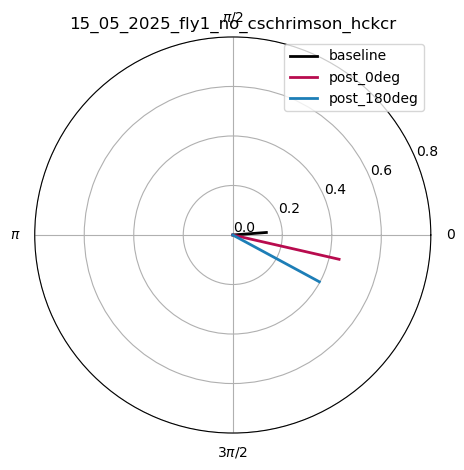

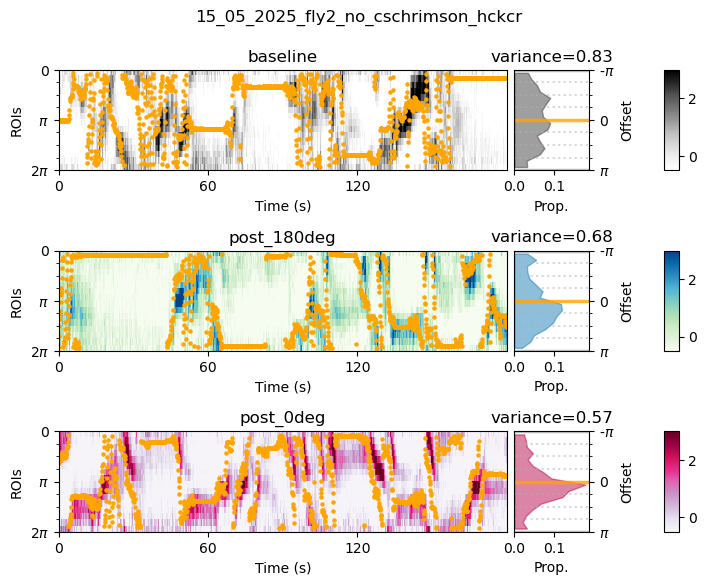

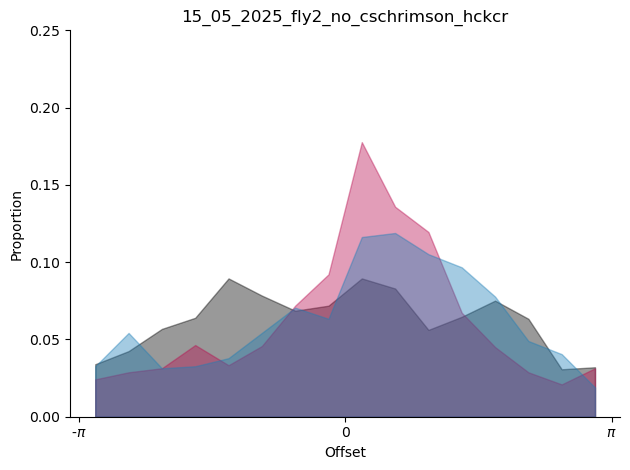

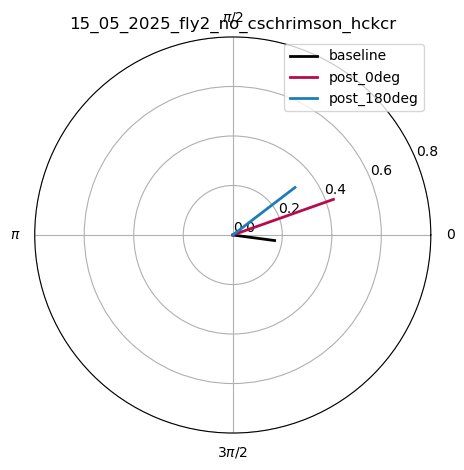

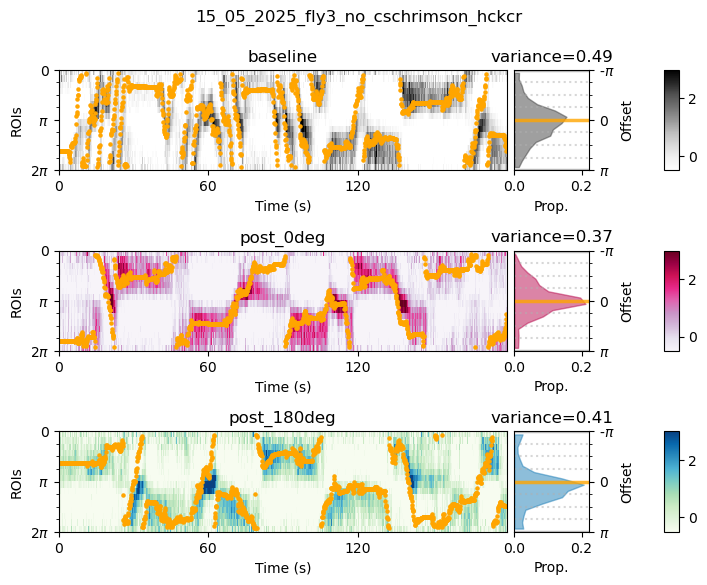

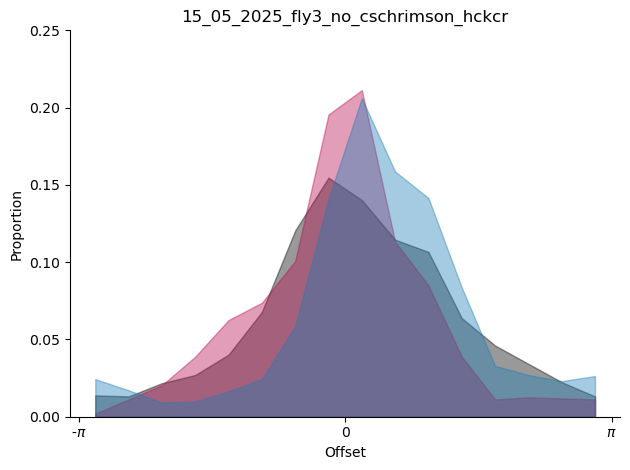

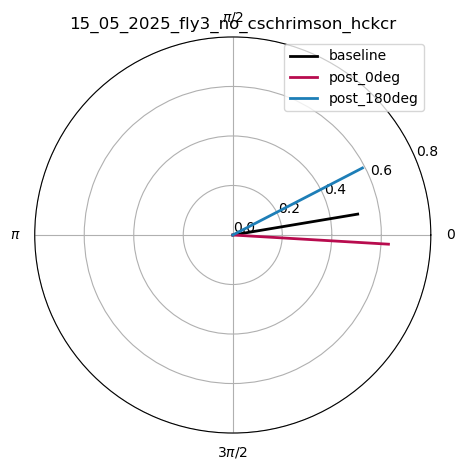

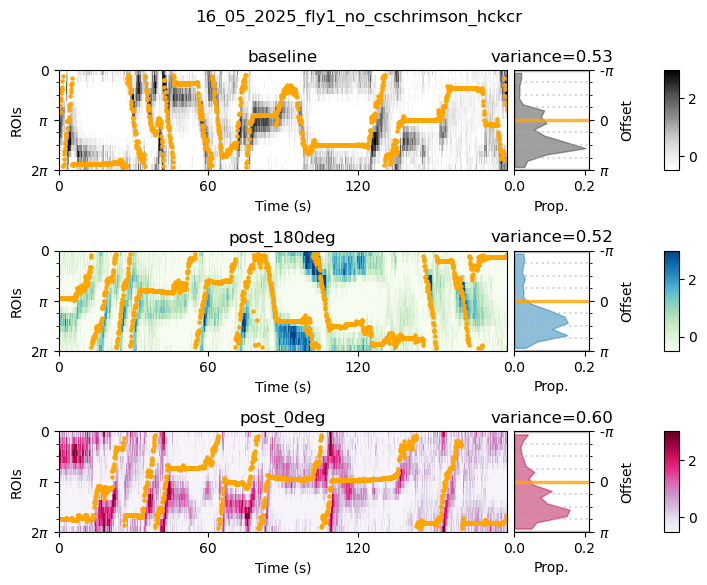

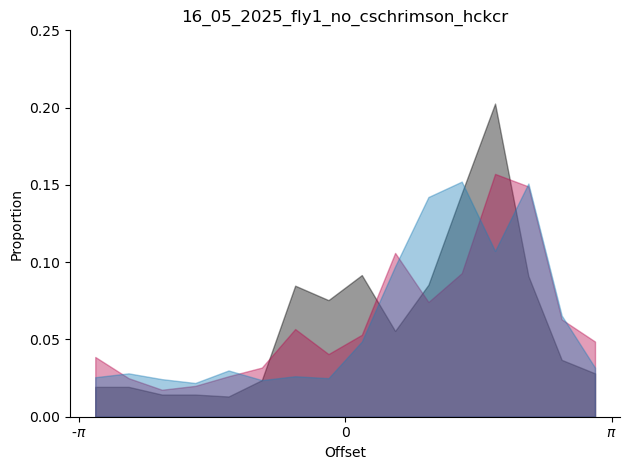

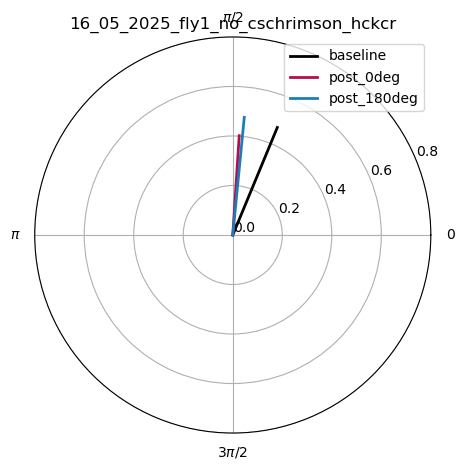

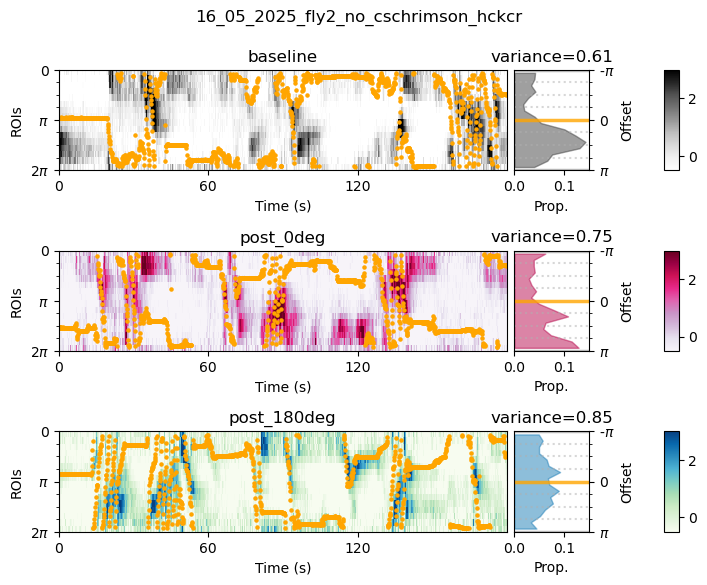

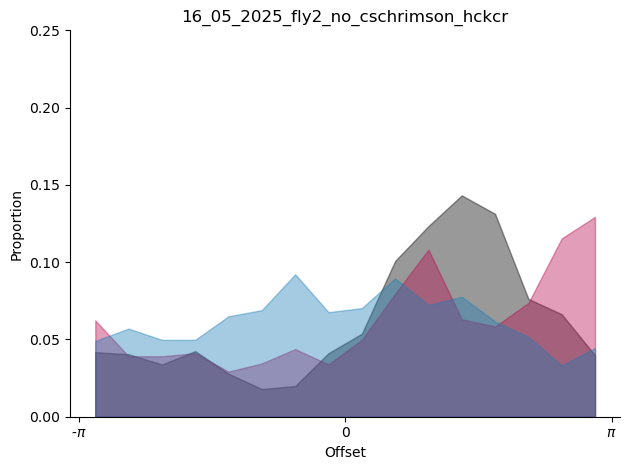

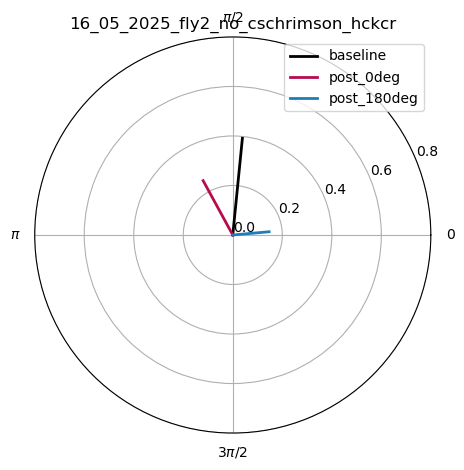

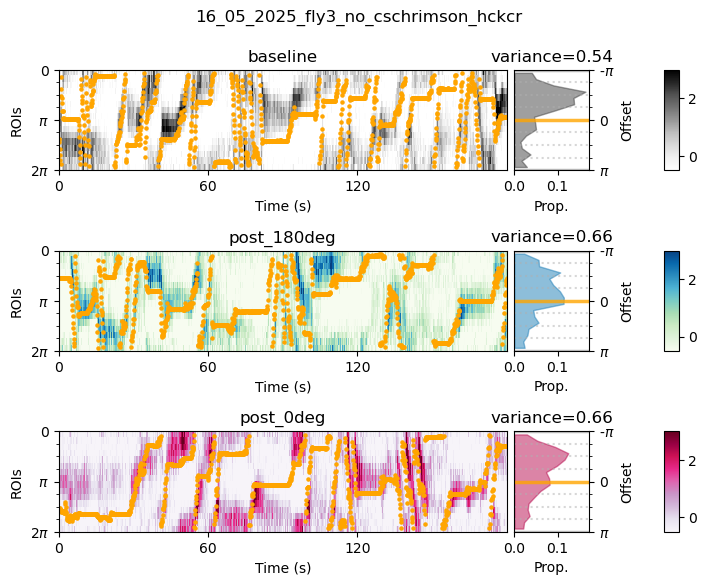

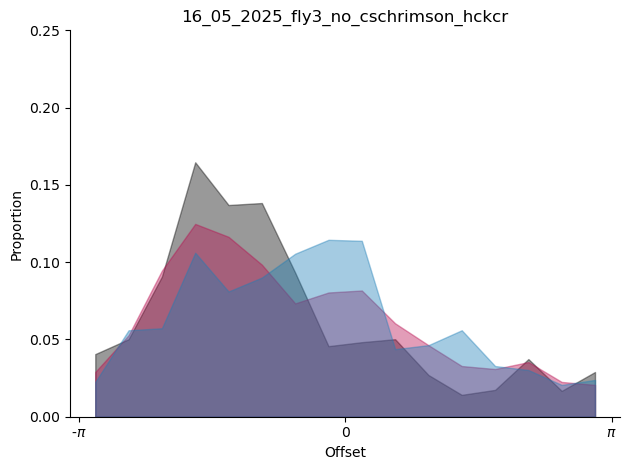

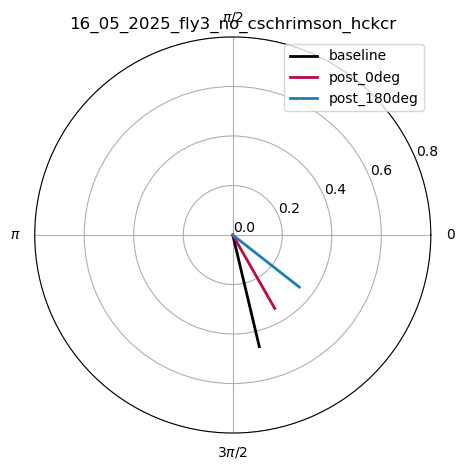

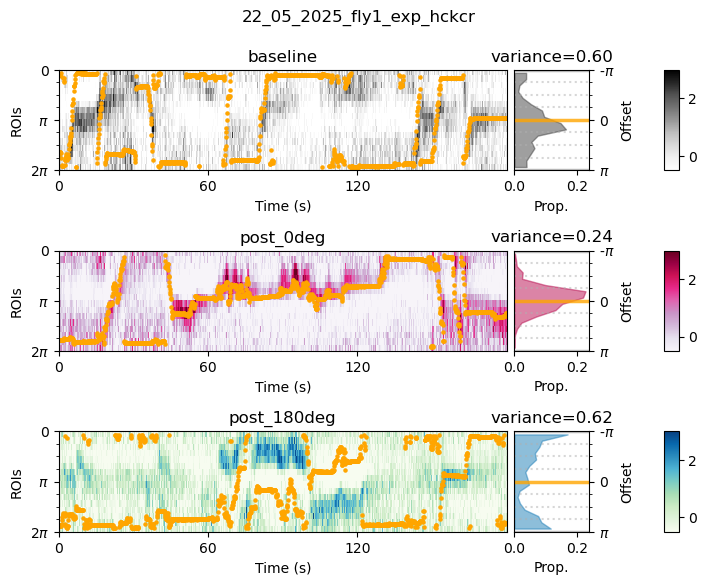

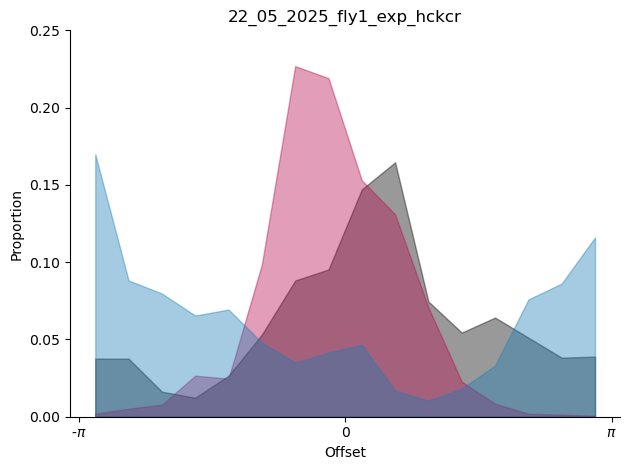

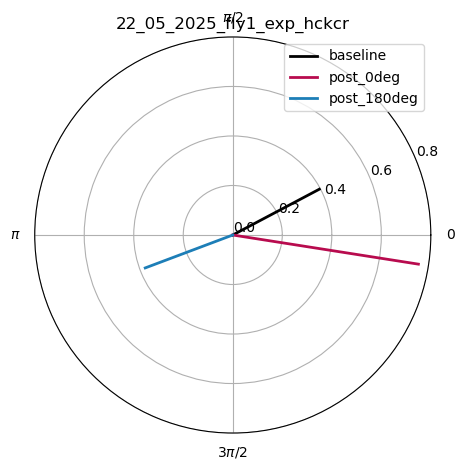

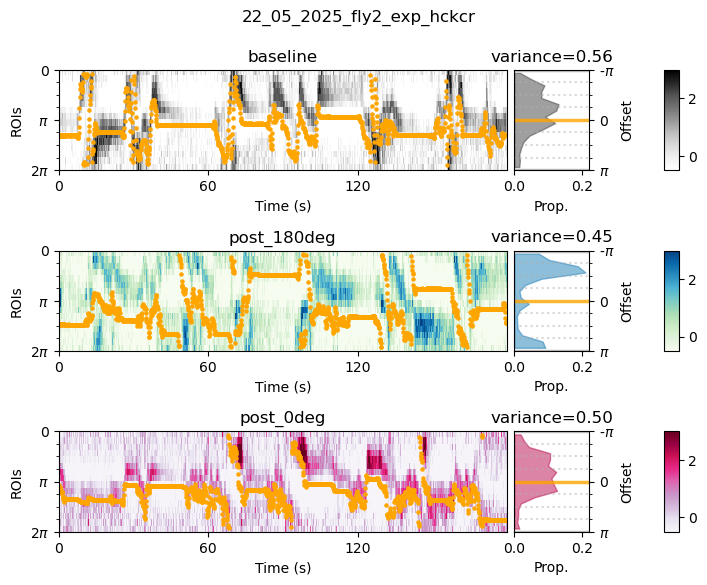

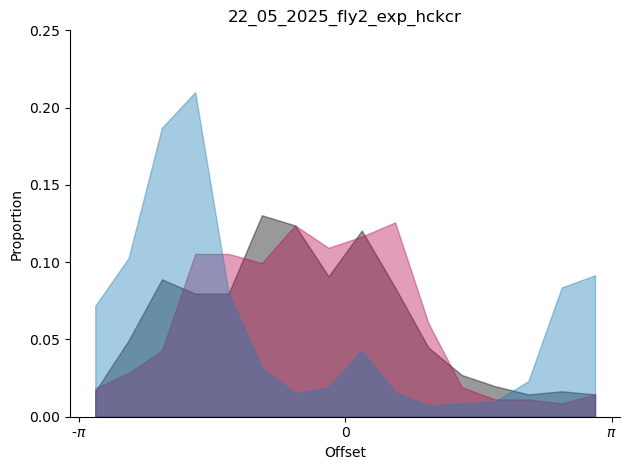

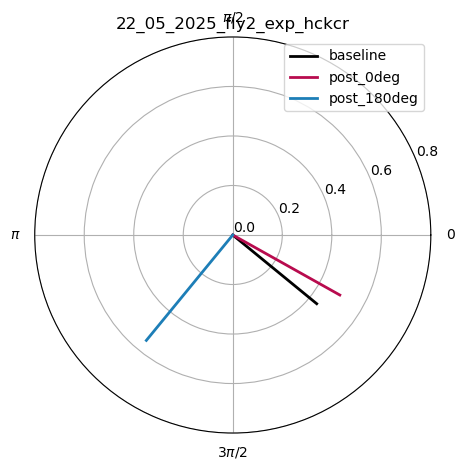

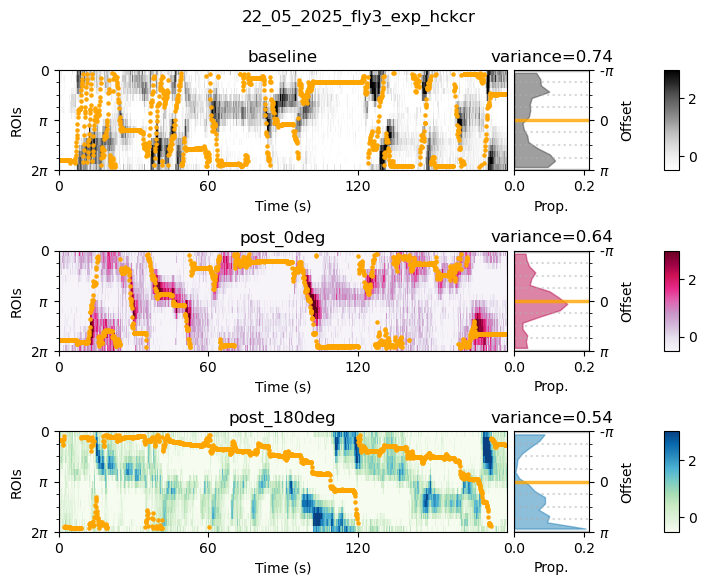

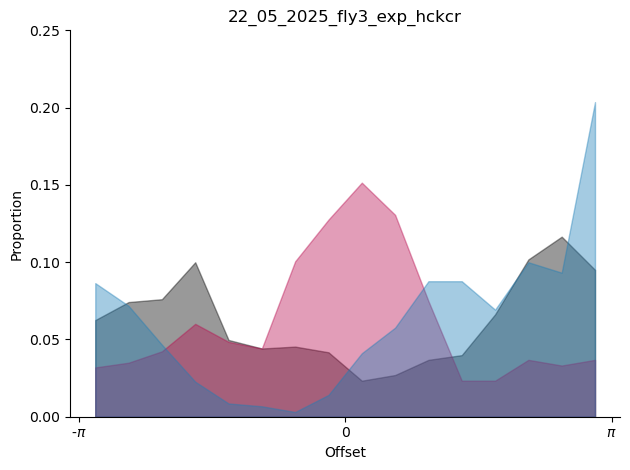

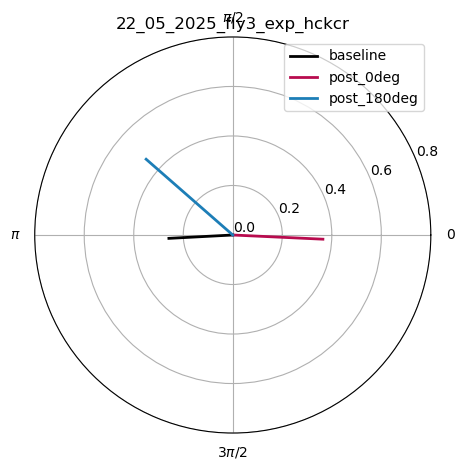

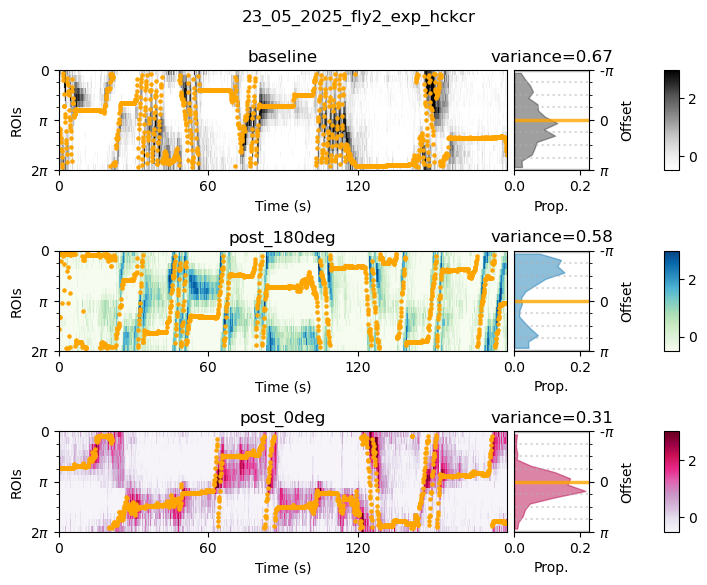

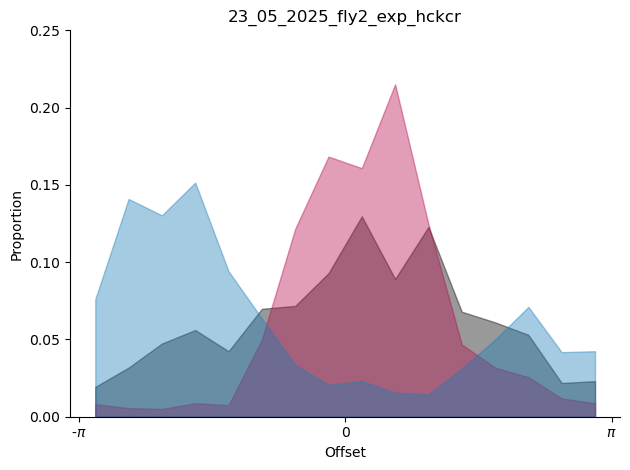

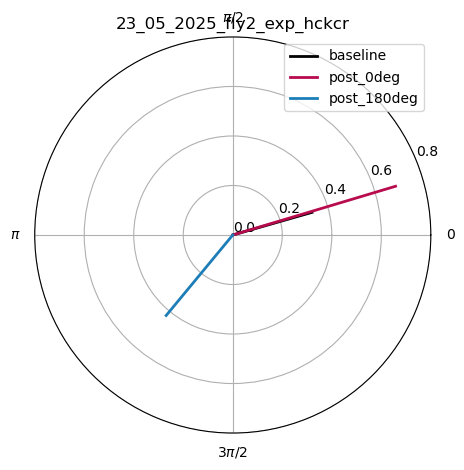

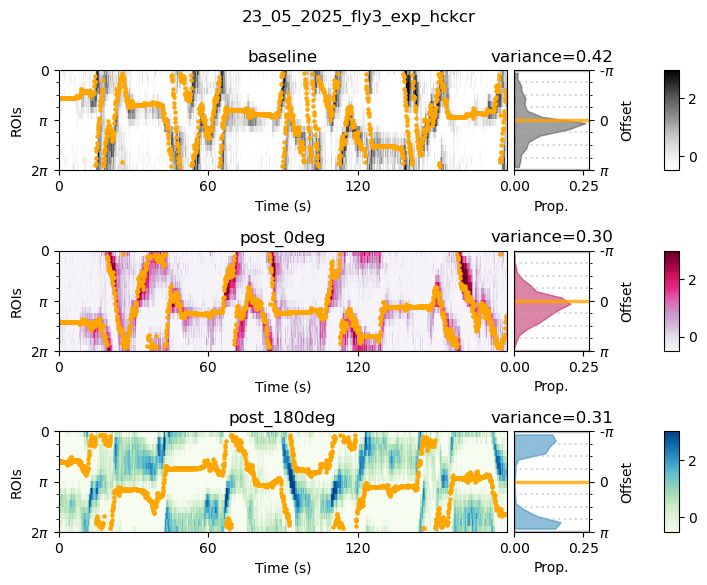

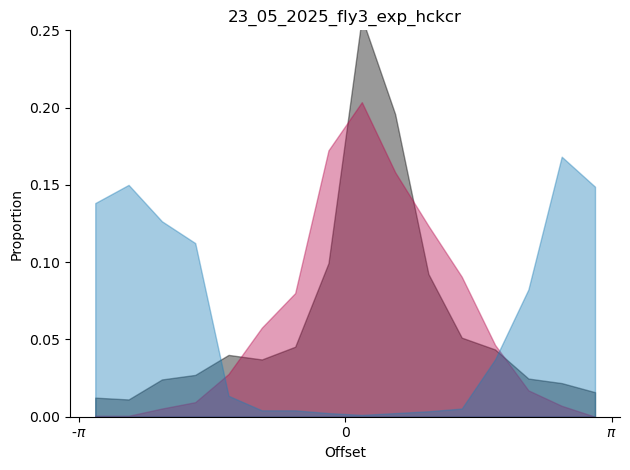

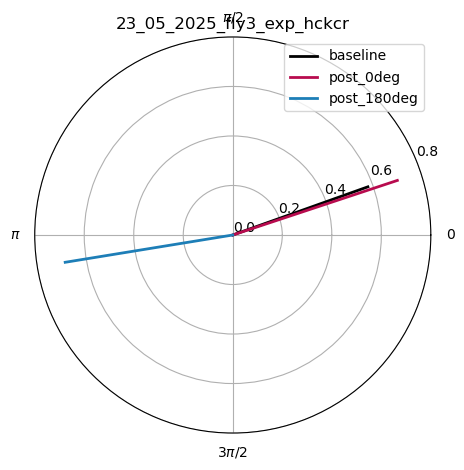

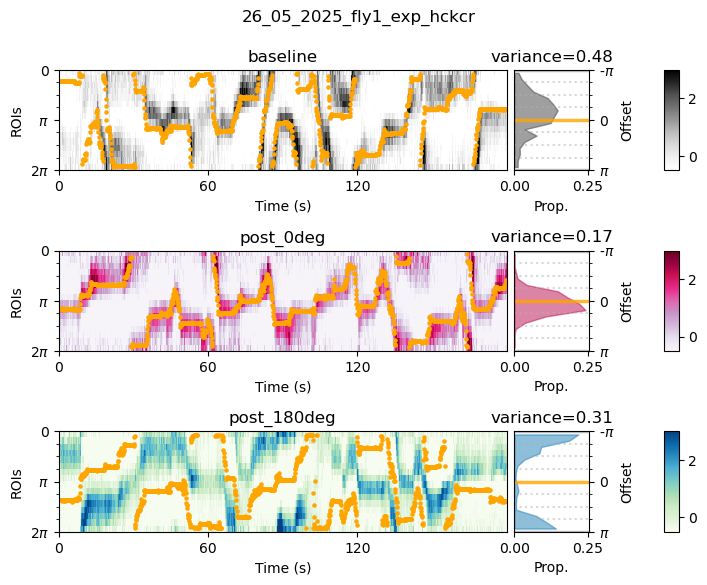

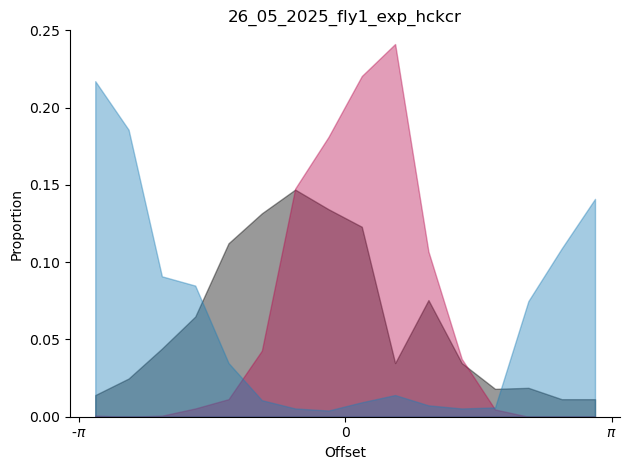

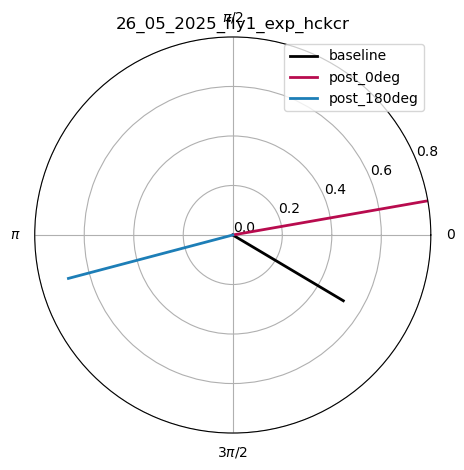

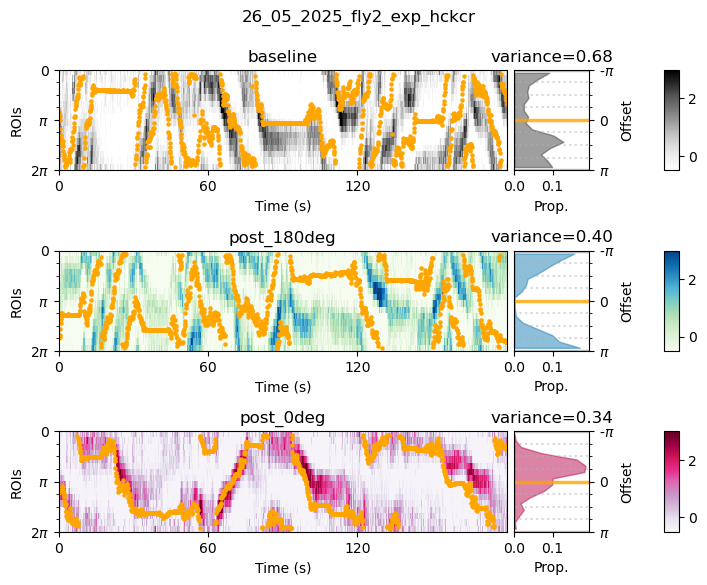

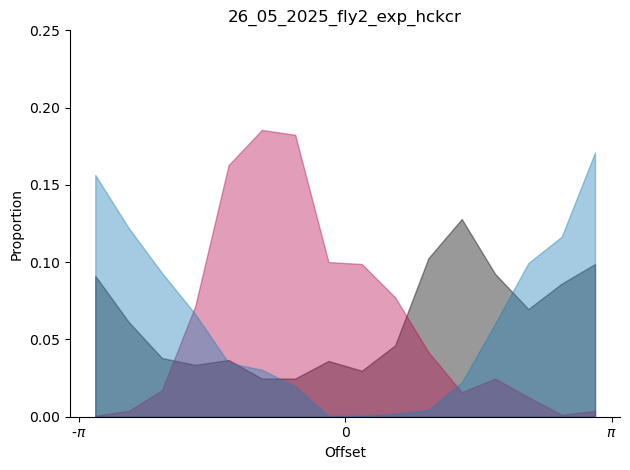

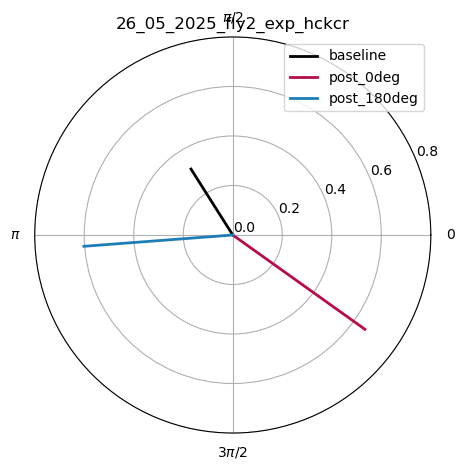

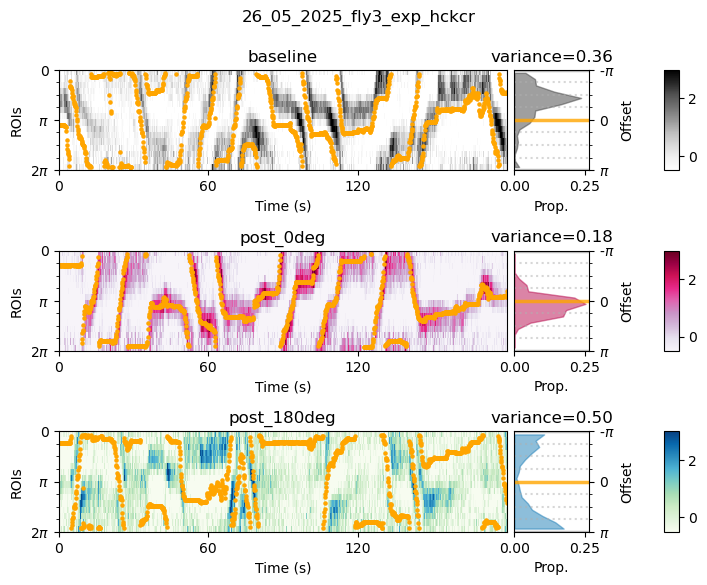

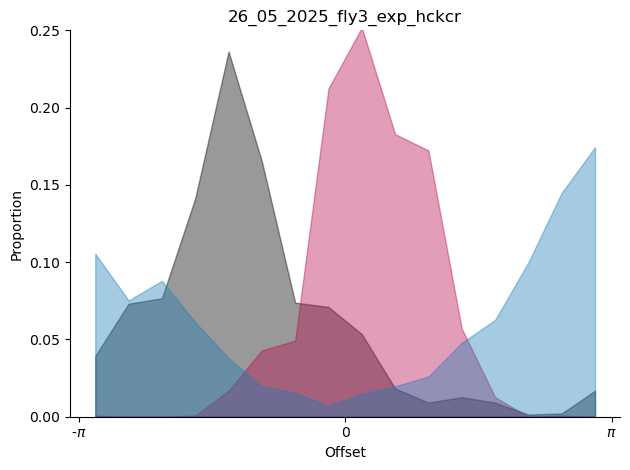

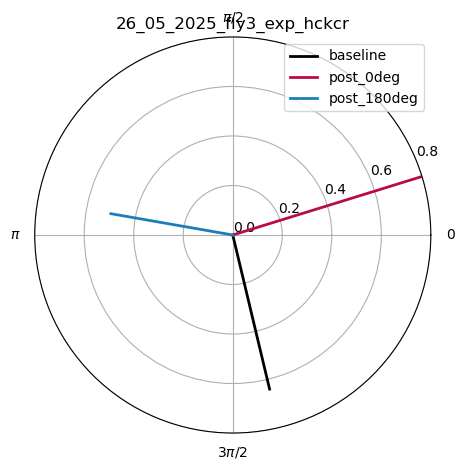

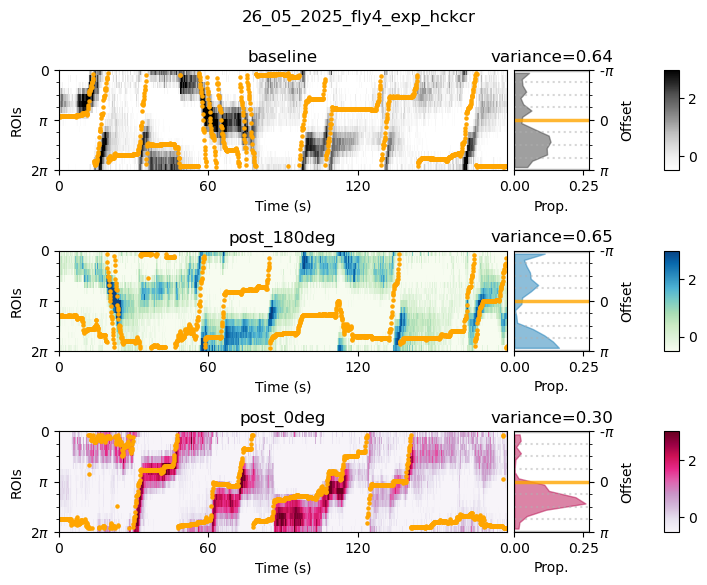

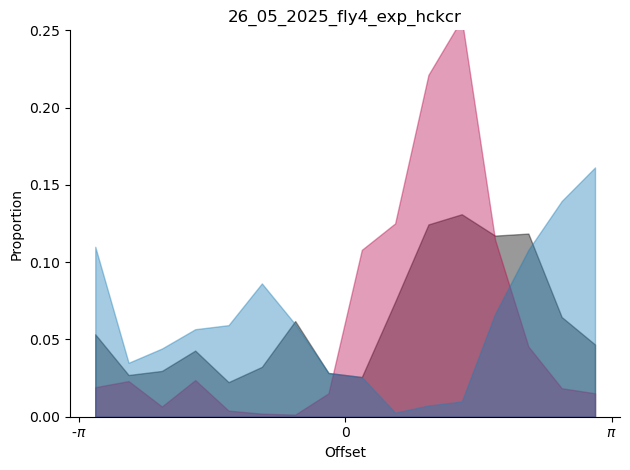

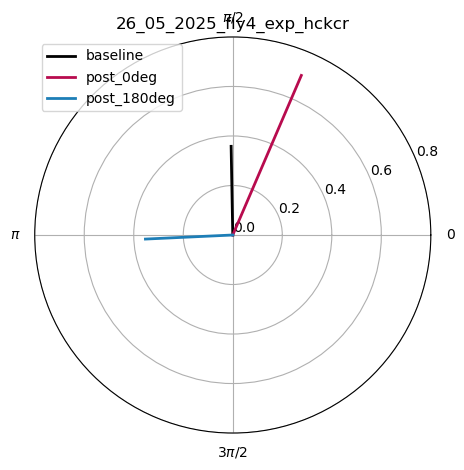

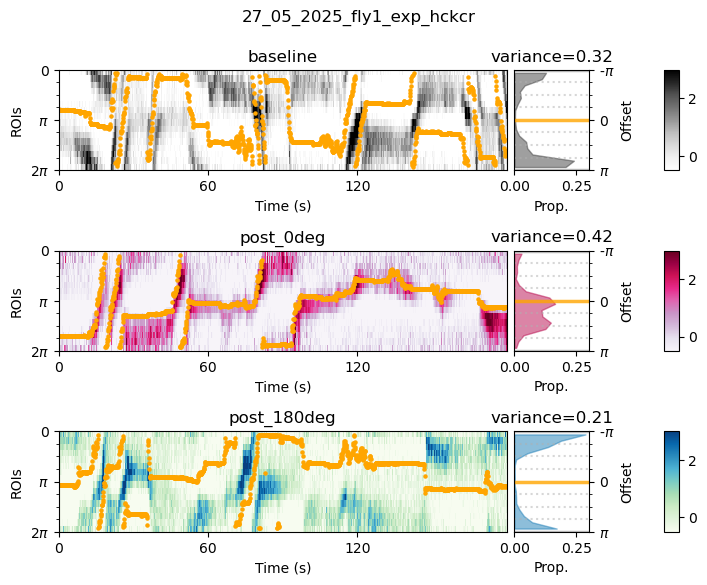

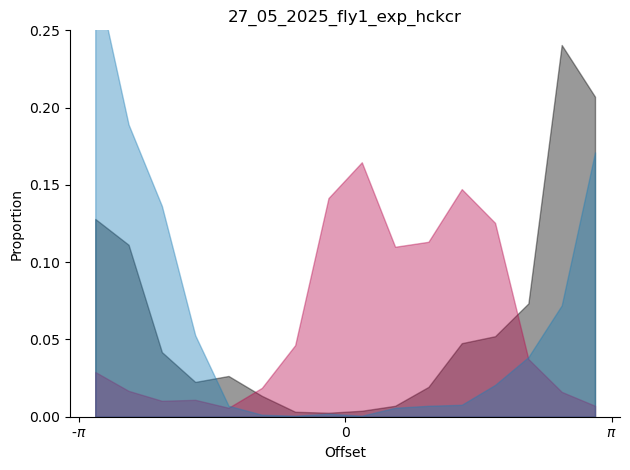

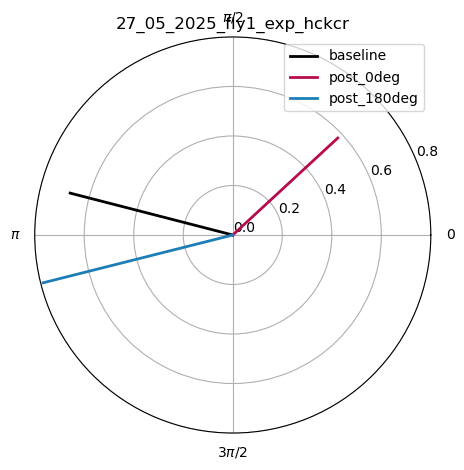

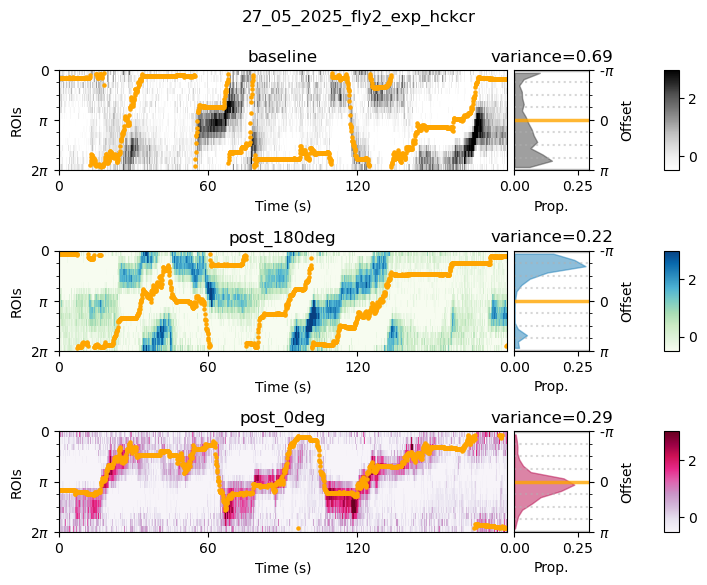

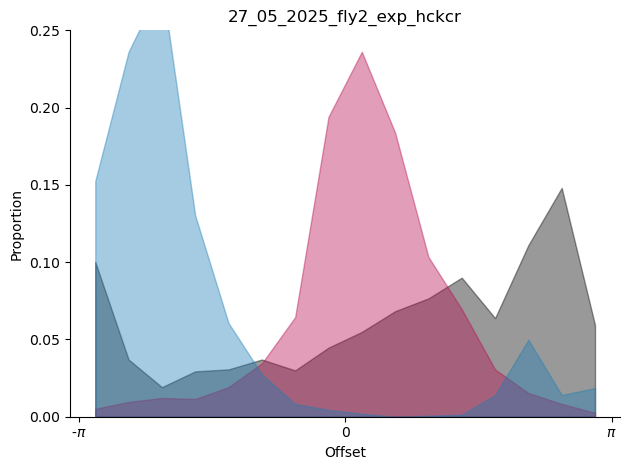

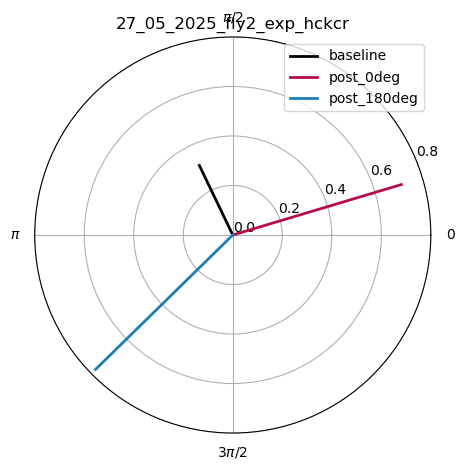

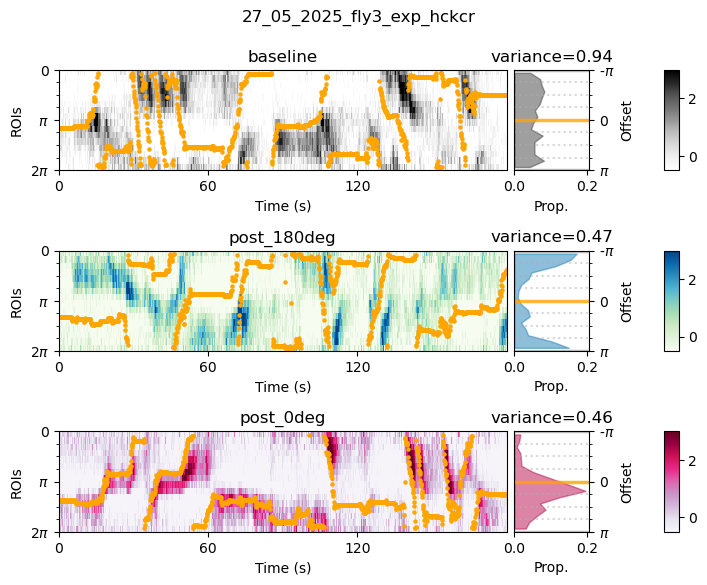

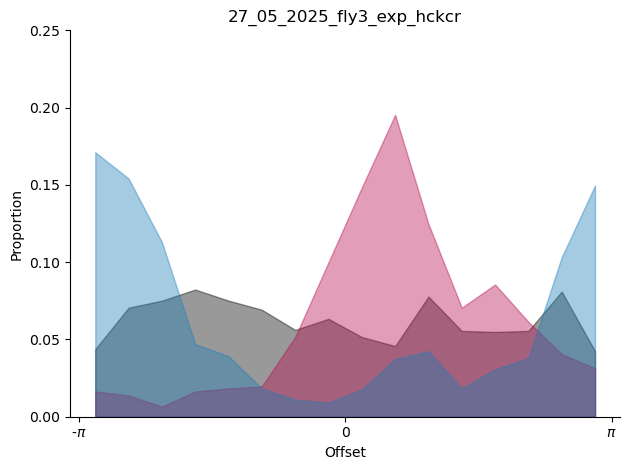

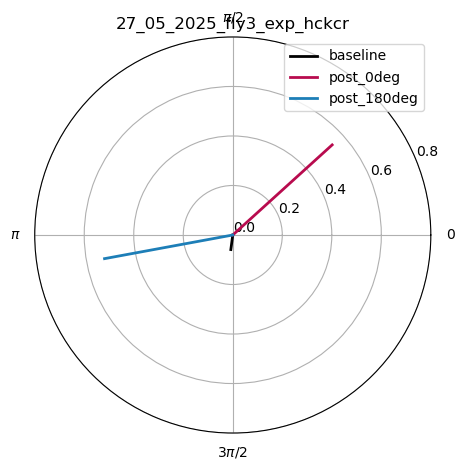

In [31]:
session_folder = figfolder / "sessions"
session_folder.mkdir(parents=True, exist_ok=True)

for fly in flies:

    baseline = sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['scan_type']=='baseline')]
    post_0deg = sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['scan_type']=='post_0deg')]
    post_180deg = sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['scan_type']=='post_180deg')]
    
    if baseline.shape[0]>0 and post_0deg.shape[0]>0 and post_180deg.shape[0]>0:

        ts_dict = {'fly': fly,
                'baseline': nmp.session.GetTS(load_row(baseline.iloc[0])),
                'post_0deg': nmp.session.GetTS(load_row(post_0deg.iloc[0])),
                'post_180deg': nmp.session.GetTS(load_row(post_180deg.iloc[0]))}
        
        sess_inds = (
            int(baseline.iloc[0]['session'][-3:]), 
            int(post_0deg.iloc[0]['session'][-3:]), 
            int(post_180deg.iloc[0]['session'][-3:]), 
        )
        sess_order = np.argsort(sess_inds)

        # fig_heatmaps, ax_heatmaps = nmp.remapping.plot_sess_heatmaps(ts_dict)
        fig_heatmaps, ax_heatmaps = nmp.remapping.plot_sess_heatmaps_w_hist(ts_dict, sess_order=sess_order)
        (fig_hist, ax_hist), (fig_polar, ax_polar) = nmp.remapping.plot_sess_histograms(ts_dict)

        
        fly_folder = session_folder / fly
        fly_folder.mkdir(parents=True, exist_ok=True)
        
        fig_heatmaps.savefig(fly_folder / "heatmaps.pdf")
        fig_hist.savefig(fly_folder / "offset_hist.pdf")
        fig_polar.savefig(fly_folder / "offset_polar.pdf")